# The Interpretation Paradox in Educational Data Mining
**A Comparative XAI Audit of Supervised and One-Class Dropout Predictors** — companion notebook.

**Run order:** execute all cells from top to bottom. Cells 1-16 reproduce the main pipeline (preprocessing, supervised models, One-Class detectors, statistical tests, SHAP/LIME audit, equity audit and two-layer simulation). Cells R1-R7 hold the additional analyses (matched-feature XAI controls, sensitivity scenarios, bootstrap equity intervals, reproducibility tables, regenerated figures).

**Data:** not included in this repository. Download the dataset (Realinho et al., Zenodo, DOI 10.5281/zenodo.5777340) and set `DATASET_PATH` (default `data/dataset.csv`). See the README. Outputs are written to `OUTPUT_DIR` (default `results/`).

**Quick test:** set the environment variable `MODO_TESTE_RAPIDO=1` to run with few trials and seeds (results will differ from the paper).

In [3]:
# %% [CELL 1] Installing Dependencies with Pinned Versions
!pip install -q optuna==3.6.1 shap==0.52.0 lime==0.2.0.1 xgboost==3.2.0 imbalanced-learn==0.13.0

In [4]:
# %% [CELL 2] Environment Setup, Directories and Global Hyperparameters
import os

IS_COLAB = False
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IS_COLAB = True
    print(' Google Drive mounted.')
except ImportError:
    print(' Outside Colab — adjust the paths.')

DATASET_PATH = os.environ.get(
    'DATASET_PATH',
    '/content/drive/MyDrive/Mestrado IFES/Artigo_Publicação/dataset.csv'
)
OUTPUT_DIR = os.environ.get(
    'OUTPUT_DIR',
    '/content/drive/MyDrive/Mestrado IFES/Dissertação de Mestrado/resultados_v4'
)

for sub in ['', 'figuras', 'tabelas', 'modelos', 'optuna_logs', 'predicoes', 'xai']:
    os.makedirs(os.path.join(OUTPUT_DIR, sub), exist_ok=True)

def caminho_saida(nome, subdir=''):
    return os.path.join(OUTPUT_DIR, subdir, nome) if subdir else os.path.join(OUTPUT_DIR, nome)

MODO_TESTE_RAPIDO = os.environ.get('MODO_TESTE_RAPIDO', '0') == '1'
if MODO_TESTE_RAPIDO:
    N_TRIALS_SUP, N_TRIALS_OC, N_TRIALS_AE = 3, 3, 2
    SEEDS_AE = SEEDS_SHAP = SEEDS_ABLACAO = SEEDS_LIME = [42, 43]
    N_BOOT, N_SHAP_INTER, N_LIME_SAMPLES = 200, 60, 1000
    print(' QUICK TEST MODE ACTIVE.')
else:
    N_TRIALS_SUP, N_TRIALS_OC, N_TRIALS_AE = 40, 40, 20
    SEEDS_AE = SEEDS_SHAP = SEEDS_ABLACAO = [42, 43, 44, 45, 46]
    SEEDS_LIME = [42, 43, 44, 45, 46]   # multi-seed to validate LIME stability
    N_BOOT, N_SHAP_INTER, N_LIME_SAMPLES = 2000, 300, 10000

OPTIMIZE_METRIC    = 'f1'
METRICA_REFERENCIA = 'MCC'
N_JOBS_CV          = -1

# --- Methodological decisions for the XAI audit (Section 3.6 of the paper) ---
XAI_K_TOP          = 10            # top-k features used in the LIME×SHAP Jaccard
N_LIME_SAMPLES_R   = 50            # number of paired samples for Jaccard (LIME is slow)
N_LIME_SEEDS       = len(SEEDS_LIME)
TOP_K_OC_FEATURES  = 20            # Top-20 features for One-Class models (Section 3.4)

print(f' Environment OK | output: {OUTPUT_DIR}')

Mounted at /content/drive
 Google Drive mounted.
 Environment OK | output: /content/drive/MyDrive/Mestrado IFES/Dissertação de Mestrado/resultados_v4


In [5]:
# %% [CELL 3] Imports, Operational Determinism and Storage Structures
import random
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np, pandas as pd
import time, json, warnings, platform, hashlib, inspect, traceback
import sklearn, xgboost, imblearn, statsmodels
from collections import Counter
from itertools import combinations

import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    confusion_matrix, f1_score, roc_auc_score, average_precision_score,
    recall_score, accuracy_score, precision_score, matthews_corrcoef,
    balanced_accuracy_score, cohen_kappa_score, brier_score_loss, log_loss,
    roc_curve, precision_recall_curve, ConfusionMatrixDisplay, jaccard_score, make_scorer
)
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor

# Resampling techniques cited in Section 3.4 of the paper
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.combine import SMOTETomek, SMOTEENN
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
import shap
from lime.lime_tabular import LimeTabularExplainer
from IPython.display import display

TSNE_ITER_KW = 'max_iter' if 'max_iter' in inspect.signature(TSNE).parameters else 'n_iter'

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
    print(' TF op determinism enabled.')
except Exception as e:
    print(f'bad {e}')

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Blues_r')

VERSOES = {
    'python': platform.python_version(), 'numpy': np.__version__,
    'pandas': pd.__version__, 'tensorflow': tf.__version__,
    'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__,
    'imbalanced-learn': imblearn.__version__, 'statsmodels': statsmodels.__version__,
    'optuna': optuna.__version__, 'shap': shap.__version__
}
print('\n=== Versions ===')
for k, v in VERSOES.items():
    print(f'  {k:15s}: {v}')
print(f'  seed            : {SEED}')

results_list, preds_store, models_store = [], {}, {}
xai_specs = {}

 TF op determinism enabled.

=== Versions ===
  python         : 3.13.16
  numpy          : 2.4.6
  pandas         : 2.2.3
  tensorflow     : 2.21.0
  scikit-learn   : 1.6.1
  xgboost        : 3.2.0
  imbalanced-learn: 0.13.0
  statsmodels    : 0.15.0
  optuna         : 3.6.1
  shap           : 0.52.0
  seed            : 42


In [6]:
# %% [CELL 4] Hardware Acceleration Check (GPU)
gpus = tf.config.list_physical_devices('GPU')
print(' GPU:' if gpus else ' CPU:', gpus if gpus else 'Autoencoder will be slower')

 GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:
# %% [CELL 5] Initial Inspection of the Raw Dataset
if not os.path.exists(DATASET_PATH):
    print(f' File not found: {DATASET_PATH}')
else:
    try:
        df_preview = pd.read_csv(DATASET_PATH, delimiter=';')
        if 'Target' not in df_preview.columns:
            raise ValueError()
    except Exception:
        df_preview = pd.read_csv(DATASET_PATH, delimiter=',')
    print(f' Raw shape: {df_preview.shape} (34 original attributes + 1 Target column)')
    display(df_preview.head())
    del df_preview

 Raw shape: (4424, 35) (34 original attributes + 1 Target column)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,10,1,0,0,1,1,0,20,0,0,0,0,0,0.0000,0,0,0,0,0,0.0000,0,10.8000,1.4000,1.7400,Dropout
1,1,6,1,11,1,1,1,1,3,4,4,1,0,0,0,1,0,19,0,0,6,6,6,14.0000,0,0,6,6,6,13.6667,0,13.9000,-0.3000,0.7900,Graduate
2,1,1,5,5,1,1,1,22,27,10,10,1,0,0,0,1,0,19,0,0,6,0,0,0.0000,0,0,6,0,0,0.0000,0,10.8000,1.4000,1.7400,Dropout
3,1,8,2,15,1,1,1,23,27,6,4,1,0,0,1,0,0,20,0,0,6,8,6,13.4286,0,0,6,10,5,12.4000,0,9.4000,-0.8000,-3.1200,Graduate
4,2,12,1,3,0,1,1,22,28,10,10,0,0,0,1,0,0,45,0,0,6,9,5,12.3333,0,0,6,6,6,13.0000,0,13.9000,-0.3000,0.7900,Graduate


 SHA-256 verified (ff327a7ed348140d...).
 4424 rows × 35 columns loaded

--- Original distribution ---
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


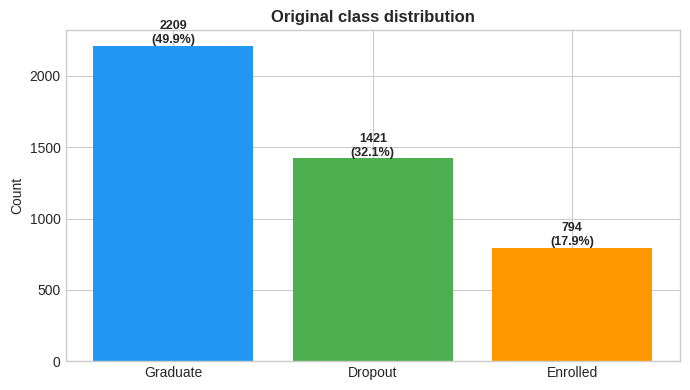


 Target binarized (1=Dropout, 0=Not Dropout)
✓ percentage_course_completed created (no leakage). 100% passed in the 1st year: 1280 (28.9%)
 Shape final de X: (4424, 35) (35 predictor attributes)

 Triple split — Train (2654, 35) | Val (885, 35) | Test (885, 35)
  Train dist.     : Counter({0: 1801, 1: 853})
  Val. dist.      : Counter({0: 601, 1: 284})
  Test dist.      : Counter({0: 601, 1: 284})

Baseline contamination: 0.3214


In [8]:
# %% [CELL 6] Preprocessing, Feature Engineering and Leakage-Free 60/20/20 Partitioning
class DataPreprocessor:
    # Frozen SHA-256 hash of the official dataset
    EXPECTED_SHA256 = 'ff327a7ed348140d42dd682df49e36331e2ca91ca41b8fb9ad911a4f5fba0f4e'

    def __init__(self, path, seed=42):
        self.data_path = path
        self.seed = seed
        self.df = self.X = self.y = self.feature_names = self.scaler = None
        self.cat_encoders = {}

    def load_data(self):
        try:
            with open(self.data_path, 'rb') as f:
                sha = hashlib.sha256(f.read()).hexdigest()
            if self.EXPECTED_SHA256 is None:
                print(f'  ℹ SHA-256 = {sha}  (copy to EXPECTED_SHA256 in the paper)')
            elif sha == self.EXPECTED_SHA256:
                print(f' SHA-256 verified ({sha[:16]}...).')
            else:
                print(f' SHA-256 mismatch: {sha[:16]}...')
        except Exception as e:
            print(f' SHA-256: {e}')
        try:
            try:
                self.df = pd.read_csv(self.data_path, delimiter=';')
                if 'Target' not in self.df.columns:
                    raise ValueError()
            except Exception:
                self.df = pd.read_csv(self.data_path, delimiter=',')
            self.df.columns = self.df.columns.str.strip().str.replace('"', '')
            print(f' {self.df.shape[0]} rows × {self.df.shape[1]} columns loaded')
            return 'Target' in self.df.columns
        except FileNotFoundError:
            print(f' {self.data_path}')
            return False

    def explore(self):
        print('\n--- Original distribution ---')
        print(self.df['Target'].value_counts())
        fig, ax = plt.subplots(figsize=(7, 4))
        tc = self.df['Target'].value_counts()
        bars = ax.bar(tc.index, tc.values, color=['#2196F3', '#4CAF50', '#FF9800'])
        for bar, val in zip(bars, tc.values):
            ax.text(bar.get_x() + bar.get_width() / 2, val + 20,
                    f'{val}\n({val / len(self.df) * 100:.1f}%)',
                    ha='center', fontweight='bold', fontsize=9)
        ax.set_title('Original class distribution', fontweight='bold')
        ax.set_ylabel('Count')
        plt.tight_layout()
        plt.savefig(caminho_saida('eda_distribuicao_classes.png', 'figuras'),
                    dpi=150, bbox_inches='tight')
        plt.show()

    def preprocess(self):
        self.df['Target'] = self.df['Target'].map(
            {'Dropout': 1, 'Enrolled': 0, 'Graduate': 0, 1: 1, 0: 0}
        )
        print('\n Target binarized (1=Dropout, 0=Not Dropout)')
        self.y = self.df['Target'].copy()
        self.X = self.df.drop('Target', axis=1).copy()

        cols = [
            'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (approved)',
            'Curricular units 1st sem (enrolled)', 'Curricular units 2nd sem (enrolled)'
        ]
        if all(c in self.X.columns for c in cols):
            a1, a2, m1, m2 = cols
            ap = self.X[a1] + self.X[a2]
            mt = self.X[m1] + self.X[m2]
            aproveitamento_total = (mt > 0) & (ap >= mt)
            razao = np.where(mt > 0, ap / mt, 0.0)
            razao = np.clip(razao, 0.0, 0.99)
            self.X['percentage_course_completed'] = np.where(aproveitamento_total, 1.0, razao)
            print(f'✓ percentage_course_completed created (no leakage). '
                  f'100% passed in the 1st year: {aproveitamento_total.sum()} '
                  f'({aproveitamento_total.mean() * 100:.1f}%)')

        self.feature_names = self.X.columns.tolist()
        for col in self.X.columns:
            if self.X[col].dtype == 'object':
                le = LabelEncoder()
                self.X[col] = le.fit_transform(self.X[col].astype(str))
                self.cat_encoders[col] = le
        print(f' Shape final de X: {self.X.shape} (35 predictor attributes)')

    def split_and_scale(self, test_size=0.20, val_size=0.25):
        X_temp, X_test_raw, y_temp, y_test = train_test_split(
            self.X, self.y, test_size=test_size, stratify=self.y, random_state=self.seed
        )
        X_train_raw, X_val_raw, y_train, y_val = train_test_split(
            X_temp, y_temp, test_size=val_size, stratify=y_temp, random_state=self.seed
        )

        # Defensive median imputation computed strictly on the training set (no data leakage)
        if X_train_raw.isnull().sum().sum() > 0 or X_val_raw.isnull().sum().sum() > 0 or X_test_raw.isnull().sum().sum() > 0:
            print(' NaN detected: median imputation fitted exclusively on the training set.')
            mediana_treino = X_train_raw.median()
            X_train_raw = X_train_raw.fillna(mediana_treino)
            X_val_raw   = X_val_raw.fillna(mediana_treino)
            X_test_raw  = X_test_raw.fillna(mediana_treino)

        # StandardScaler fitted strictly on the training data
        self.scaler = StandardScaler().fit(X_train_raw)
        X_train = self.scaler.transform(X_train_raw)
        X_val   = self.scaler.transform(X_val_raw)
        X_test  = self.scaler.transform(X_test_raw)

        print(f'\n Triple split — Train {X_train.shape} | Val {X_val.shape} | Test {X_test.shape}')
        print(f'  Train dist.     : {Counter(y_train)}')
        print(f'  Val. dist.      : {Counter(y_val)}')
        print(f'  Test dist.      : {Counter(y_test)}')
        return (X_train, X_val, X_test, y_train.values, y_val.values, y_test.values,
                X_train_raw, X_val_raw, X_test_raw)


preprocessor = DataPreprocessor(DATASET_PATH, SEED)
if preprocessor.load_data():
    preprocessor.explore()
    preprocessor.preprocess()
    (X_train, X_val, X_test, y_train, y_val, y_test,
     X_train_raw, X_val_raw, X_test_raw) = preprocessor.split_and_scale()
    feature_names = preprocessor.feature_names
    scaler = preprocessor.scaler
    X_train_normal = X_train[y_train == 0]
    contamination_rate = max(0.01, float((y_train == 1).sum()) / len(y_train))
    print(f'\nBaseline contamination: {contamination_rate:.4f}')
    DATA_READY = True
else:
    DATA_READY = False

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0000,1.1786,0.6057,1.0000,1.0000,1.0000,1.0000,6.0000
Application mode,4424.0000,6.8870,5.2990,1.0000,1.0000,8.0000,12.0000,18.0000
Application order,4424.0000,1.7278,1.3138,0.0000,1.0000,1.0000,2.0000,9.0000
Course,4424.0000,9.8992,4.3318,1.0000,6.0000,10.0000,13.0000,17.0000
Daytime/evening attendance,4424.0000,0.8908,0.3119,0.0000,1.0000,1.0000,1.0000,1.0000
Previous qualification,4424.0000,2.5314,3.9637,1.0000,1.0000,1.0000,1.0000,17.0000
Nacionality,4424.0000,1.2545,1.7484,1.0000,1.0000,1.0000,1.0000,21.0000
Mother's qualification,4424.0000,12.3221,9.0263,1.0000,2.0000,13.0000,22.0000,29.0000
Father's qualification,4424.0000,16.4552,11.0448,1.0000,3.0000,14.0000,27.0000,34.0000
Mother's occupation,4424.0000,7.3178,3.9978,1.0000,5.0000,6.0000,10.0000,32.0000


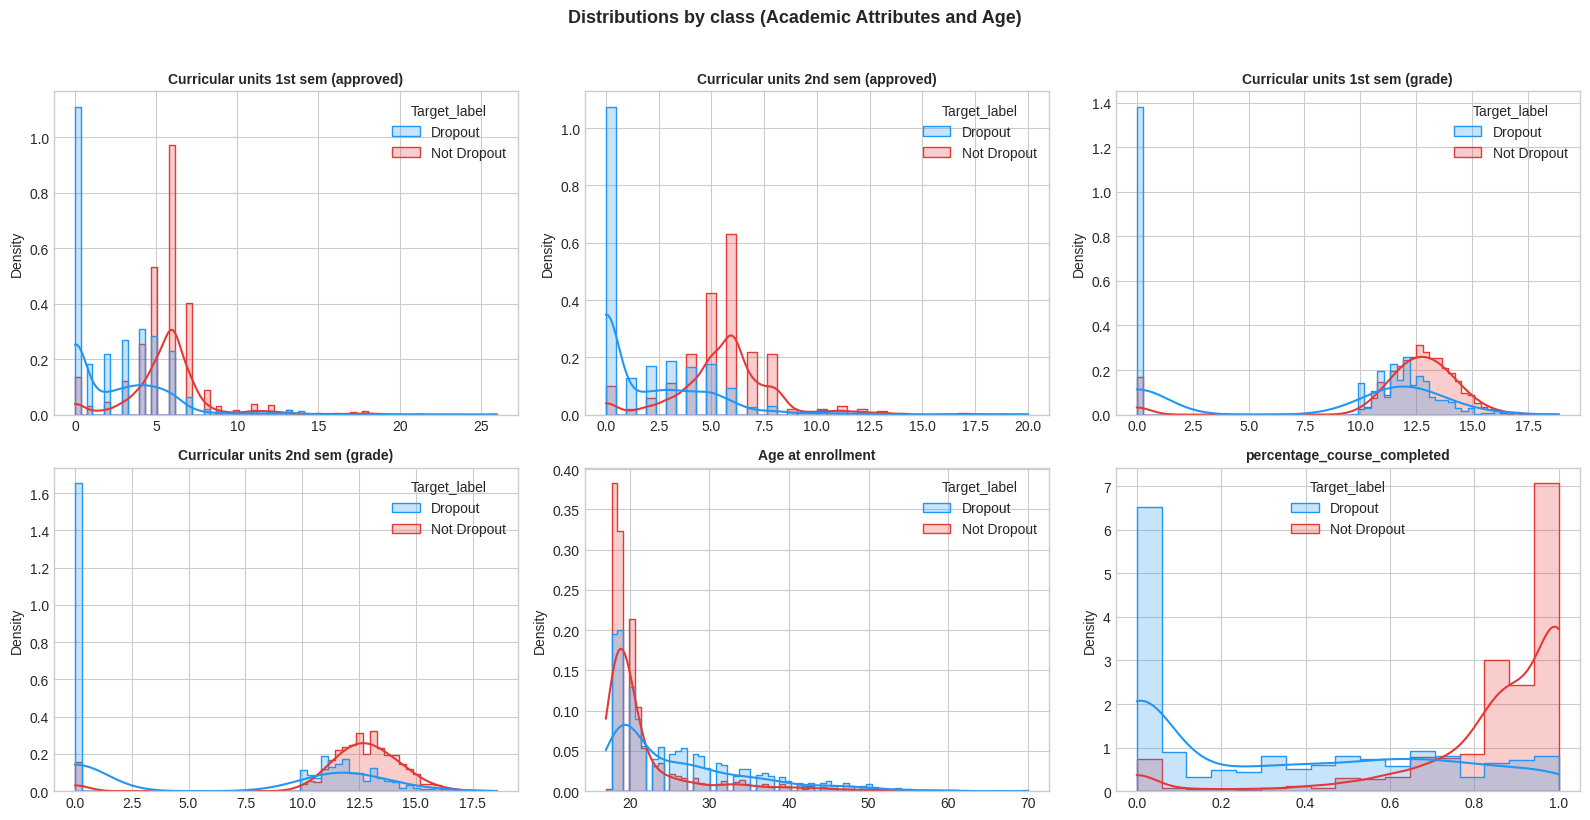

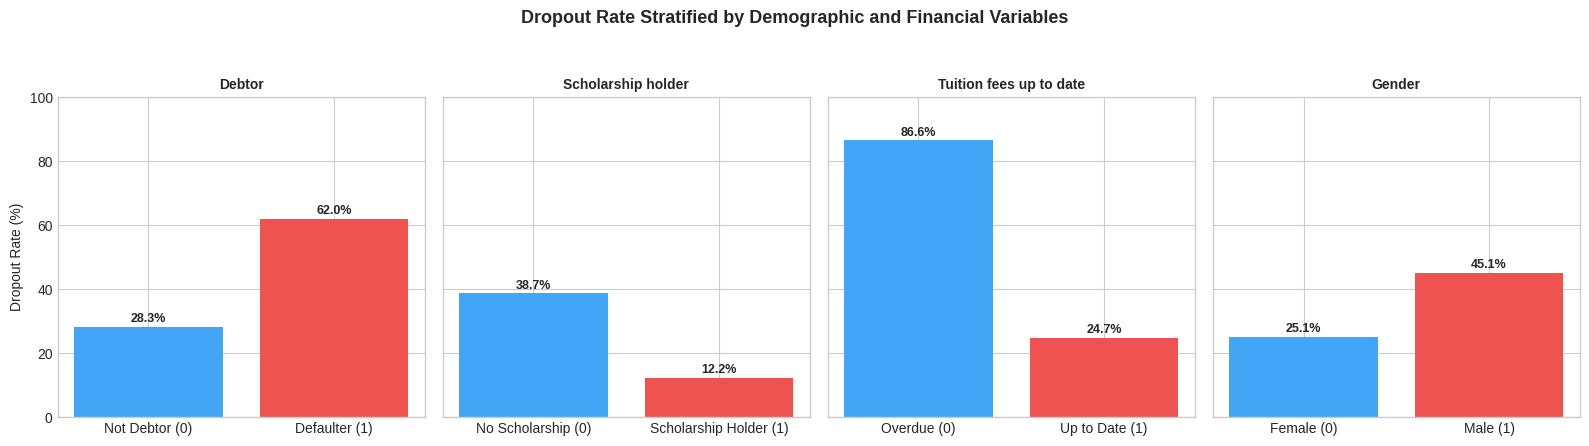

In [9]:
# %% [CELL 7] Exploratory Data Analysis
if DATA_READY:
    df_eda = preprocessor.X.copy()
    df_eda['Target'] = preprocessor.y.values
    df_eda['Target_label'] = df_eda['Target'].map({0: 'Not Dropout', 1: 'Dropout'})
    display(df_eda.drop(columns=['Target_label']).describe().T)
    df_eda.drop(columns=['Target_label']).describe().T.to_csv(
        caminho_saida('eda_describe.csv', 'tabelas')
    )

    # --- FIGURE 1: Academic Distributions ---
    vars_acad = [
        'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (approved)',
        'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)',
        'Age at enrollment', 'percentage_course_completed'
    ]
    vars_acad = [v for v in vars_acad if v in df_eda.columns]
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    axes = axes.ravel()
    for i, col in enumerate(vars_acad):
        sns.histplot(
            data=df_eda, x=col, hue='Target_label', kde=True,
            element='step', stat='density', common_norm=False,
            ax=axes[i], palette=['#2196F3', '#E53935']
        )
        axes[i].set_title(col, fontsize=10, fontweight='bold')
        axes[i].set_xlabel('')
    plt.suptitle('Distributions by class (Academic Attributes and Age)', fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(caminho_saida('eda_distribuicoes_academicas.png', 'figuras'),
                dpi=200, bbox_inches='tight')
    plt.show()

    # --- FIGURE 2: Dropout Rate by Sociodemographic Categorical Variables (Section 3.2) ---
    vars_demo = {
        'Debtor': {0: 'Not Debtor (0)', 1: 'Defaulter (1)'},
        'Scholarship holder': {0: 'No Scholarship (0)', 1: 'Scholarship Holder (1)'},
        'Tuition fees up to date': {0: 'Overdue (0)', 1: 'Up to Date (1)'},
        'Gender': {0: 'Female (0)', 1: 'Male (1)'}
    }
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
    for i, (col, mapa) in enumerate(vars_demo.items()):
        if col in df_eda.columns:
            taxas = df_eda.groupby(col)['Target'].mean() * 100
            labels_cat = [mapa.get(k, str(k)) for k in taxas.index]
            bars = axes[i].bar(labels_cat, taxas.values, color=['#42A5F5', '#EF5350'][:len(taxas)])
            for bar, v in zip(bars, taxas.values):
                axes[i].text(bar.get_x() + bar.get_width() / 2, v + 1.5,
                             f'{v:.1f}%', ha='center', fontweight='bold', fontsize=9)
            axes[i].set_title(col, fontsize=10, fontweight='bold')
            axes[i].set_ylim(0, 100)
            if i == 0:
                axes[i].set_ylabel('Dropout Rate (%)')
    plt.suptitle('Dropout Rate Stratified by Demographic and Financial Variables',
                 fontsize=13, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.savefig(caminho_saida('eda_taxa_evasao_demografico.png', 'figuras'),
                dpi=200, bbox_inches='tight')
    plt.show()

In [10]:
# %% [CELL 8] Evaluation Functions, Statistical Tests, Calibration, DCA, Fairness and Two-Layer System
if DATA_READY:

    def evaluate_model(model_name, abordagem, y_true, y_pred, y_prob=None,
                       training_time=0.0, plot_cm=True, save_prefix='v4',
                       prob_calibrated=True):
        try:
            f1 = f1_score(y_true, y_pred, zero_division=0)
            rec = recall_score(y_true, y_pred, zero_division=0)
            prec = precision_score(y_true, y_pred, zero_division=0)
            acc = accuracy_score(y_true, y_pred)
            mcc = matthews_corrcoef(y_true, y_pred)
            bacc = balanced_accuracy_score(y_true, y_pred)
            kappa = cohen_kappa_score(y_true, y_pred)
            cm = confusion_matrix(y_true, y_pred)
            tn, fp, fn, tp = cm.ravel() if cm.shape == (2, 2) else (0, 0, 0, 0)
            spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
            gmean = np.sqrt(rec * spec) if (rec * spec) >= 0 else 0.0

            if y_prob is not None:
                roc_auc = roc_auc_score(y_true, y_prob)
                pr_auc  = average_precision_score(y_true, y_prob)
                if prob_calibrated:
                    brier = brier_score_loss(y_true, np.clip(y_prob, 0.0, 1.0))
                    try:
                        logloss = log_loss(y_true, np.clip(y_prob, 1e-15, 1 - 1e-15))
                    except Exception:
                        logloss = np.nan
                else:
                    brier, logloss = np.nan, np.nan
            else:
                roc_auc = roc_auc_score(y_true, y_pred)
                pr_auc, brier, logloss = 0.0, np.nan, np.nan

            metrics = {
                'Model': model_name, 'Approach': abordagem,
                'F1-Score': round(f1, 4), 'Recall': round(rec, 4),
                'Precision': round(prec, 4), 'Accuracy': round(acc, 4),
                'BalancedAcc': round(bacc, 4), 'Specificity': round(spec, 4),
                'G-Mean': round(gmean, 4), 'MCC': round(mcc, 4),
                'Kappa': round(kappa, 4), 'AUC-ROC': round(roc_auc, 4),
                'AUC-PR': round(pr_auc, 4),
                'Brier': round(brier, 4) if not np.isnan(brier) else np.nan,
                'LogLoss': round(logloss, 4) if not np.isnan(logloss) else np.nan,
                'Training Time': round(training_time, 2),
                'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn)
            }
            print(f'\n{"="*55}\n  Model: {model_name}\n{"="*55}')
            print(f'  F1={f1:.4f}  Recall={rec:.4f}  Precision={prec:.4f}  Acc={acc:.4f}')
            print(f'  AUC-ROC={roc_auc:.4f}  AUC-PR={pr_auc:.4f}  Brier={brier if not np.isnan(brier) else -1:.4f}')
            print(f'  MCC={mcc:.4f}  Kappa={kappa:.4f}  G-Mean={gmean:.4f}')
            print(f'  TP={tp} FP={fp} FN={fn} TN={tn}  Time={training_time:.2f}s')

            preds_store[model_name] = {
                'y_pred': np.asarray(y_pred).astype(int),
                'y_prob': None if y_prob is None else np.asarray(y_prob, dtype=float),
                'prob_calibrated': bool(prob_calibrated),
                'abordagem': abordagem
            }
        except Exception as e:
            print(f' {model_name}: {e}')
            traceback.print_exc()
            return None

        if plot_cm:
            try:
                fig, ax = plt.subplots(figsize=(5, 4))
                ConfusionMatrixDisplay(
                    confusion_matrix=cm,
                    display_labels=['Not Dropout', 'Dropout']
                ).plot(ax=ax, cmap='Blues', colorbar=False)
                ax.set_title(f'Confusion Matrix — {model_name}', fontsize=11, fontweight='bold')
                plt.tight_layout()
                safe = model_name.replace(' ', '_').replace('(', '').replace(')', '').replace('/', '').replace('+', '')
                plt.savefig(caminho_saida(f'cm_{save_prefix}_{safe}.png', 'figuras'),
                            dpi=150, bbox_inches='tight')
                plt.show()
            except Exception as e:
                print(f'   CM: {e}')
        return metrics

    # --- Vectorized paired bootstrap ---
    def _metrics_from_counts(tp, fp, fn, tn):
        tp, fp, fn, tn = [np.asarray(v, dtype=float) for v in (tp, fp, fn, tn)]
        with np.errstate(divide='ignore', invalid='ignore'):
            prec = np.where(tp + fp > 0, tp / (tp + fp), 0.0)
            rec  = np.where(tp + fn > 0, tp / (tp + fn), 0.0)
            spec = np.where(tn + fp > 0, tn / (tn + fp), 0.0)
            f1   = np.where(2 * tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn), 0.0)
            den  = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
            mcc  = np.where(den > 0, (tp * tn - fp * fn) / den, 0.0)
        return {'F1': f1, 'Recall': rec, 'Precision': prec, 'Specificity': spec,
                'MCC': mcc, 'BalancedAcc': (rec + spec) / 2.0}

    def paired_bootstrap(y_true, preds_dict, n_boot=2000, seed=SEED):
        y_true = np.asarray(y_true).astype(int)
        n = len(y_true)
        rng = np.random.RandomState(seed)
        idx = rng.randint(0, n, size=(n_boot, n))
        yt = y_true[idx]
        m_pos = yt.sum(axis=1).astype(float)
        m_neg = n - m_pos
        valid = (m_pos > 0) & (m_neg > 0)
        out = {}
        for name, d in preds_dict.items():
            yp = np.asarray(d['y_pred']).astype(int)[idx]
            tp = ((yt == 1) & (yp == 1)).sum(axis=1)
            fp = ((yt == 0) & (yp == 1)).sum(axis=1)
            fn = ((yt == 1) & (yp == 0)).sum(axis=1)
            tn = ((yt == 0) & (yp == 0)).sum(axis=1)
            res = _metrics_from_counts(tp, fp, fn, tn)
            if d.get('y_prob') is not None:
                pr = np.asarray(d['y_prob'], dtype=float)[idx]
                ranks = stats.rankdata(pr, axis=1)
                with np.errstate(divide='ignore', invalid='ignore'):
                    res['AUC-ROC'] = ((ranks * (yt == 1)).sum(axis=1)
                                      - m_pos * (m_pos + 1) / 2.0) / (m_pos * m_neg)
            for k in res:
                res[k] = np.where(valid, res[k], np.nan)
            out[name] = res
        return out

    def summarize_bootstrap(arr, alpha=0.05):
        a = np.asarray(arr)
        a = a[~np.isnan(a)]
        lo, hi = np.percentile(a, [100 * alpha / 2.0, 100 * (1.0 - alpha / 2.0)])
        return float(np.mean(a)), float(lo), float(hi)

    def paired_delta_pvalue(delta):
        d = np.asarray(delta)
        d = d[~np.isnan(d)]
        p = 2.0 * min((np.sum(d <= 0) + 1) / (len(d) + 1), (np.sum(d >= 0) + 1) / (len(d) + 1))
        return float(min(p, 1.0))

    # --- DeLong test (with numerical protection against zero variance) ---
    def _compute_midrank(x):
        J = np.argsort(x)
        Z = x[J]
        N = len(x)
        T = np.zeros(N, dtype=float)
        i = 0
        while i < N:
            j = i
            while j < N and Z[j] == Z[i]:
                j += 1
            T[i:j] = 0.5 * (i + j - 1) + 1
            i = j
        T2 = np.empty(N, dtype=float)
        T2[J] = T
        return T2

    def _fast_delong(preds_sorted, m):
        n = preds_sorted.shape[1] - m
        pos = preds_sorted[:, :m]
        neg = preds_sorted[:, m:]
        k = preds_sorted.shape[0]
        tx = np.empty([k, m])
        ty = np.empty([k, n])
        tz = np.empty([k, m + n])
        for r in range(k):
            tx[r, :] = _compute_midrank(pos[r, :])
            ty[r, :] = _compute_midrank(neg[r, :])
            tz[r, :] = _compute_midrank(preds_sorted[r, :])
        aucs = tz[:, :m].sum(axis=1) / m / n - float(m + 1) / 2.0 / n
        v01 = (tz[:, :m] - tx) / n
        v10 = 1.0 - (tz[:, m:] - ty) / m
        sx = np.cov(v01)
        sy = np.cov(v10)
        return aucs, sx / m + sy / n

    def delong_test(y_true, s1, s2):
        order = np.argsort(-y_true)
        yt = np.asarray(y_true)[order]
        preds = np.vstack([np.asarray(s1)[order], np.asarray(s2)[order]])
        m = int(yt.sum())
        aucs, cov = _fast_delong(preds, m)
        L = np.array([[1.0, -1.0]])
        denom = float(np.sqrt(max(0.0, float((L @ cov @ L.T).item()))))
        if denom <= 1e-12:
            return float(aucs[0]), float(aucs[1]), 0.0, 1.0
        z = float((L @ aucs).item() / denom)
        p = float(2.0 * (1.0 - stats.norm.cdf(abs(z))))
        return float(aucs[0]), float(aucs[1]), z, p

    # --- McNemar + Holm-Bonferroni correction ---
    def holm_correction(p):
        p = np.asarray(p, dtype=float)
        n = len(p)
        order = np.argsort(p)
        adj = np.empty(n)
        running = 0.0
        for rank, idx in enumerate(order):
            val = (n - rank) * p[idx]
            running = max(running, val)
            adj[idx] = running
        return np.minimum(adj, 1.0)

    def mcnemar_test(y_true, p1, p2):
        y_true = np.asarray(y_true)
        c1 = (p1 == y_true)
        c2 = (p2 == y_true)
        table = [
            [int(np.sum(c1 & c2)), int(np.sum(c1 & ~c2))],
            [int(np.sum(~c1 & c2)), int(np.sum(~c1 & ~c2))]
        ]
        nd = table[0][1] + table[1][0]
        if nd == 0:
            return 0.0, 1.0
        res = mcnemar(table, exact=(nd < 25), correction=True)
        return float(res.statistic), float(res.pvalue)

    # --- Calibration Curve and Decision Curve Analysis (DCA) ---
    def calibration_plot(y_true, prob_list, name_list, n_bins=10, fname='calibracao.png'):
        fig, ax = plt.subplots(figsize=(6, 5))
        ax.plot([0, 1], [0, 1], 'k--', label='Perfectly Calibrated')
        for p, n in zip(prob_list, name_list):
            try:
                p_clip = np.clip(np.asarray(p, dtype=float), 0.0, 1.0)
                frac, mp = calibration_curve(y_true, p_clip, n_bins=n_bins, strategy='quantile')
                ax.plot(mp, frac, marker='o', linewidth=1.8, label=n)
            except Exception:
                pass
        ax.set_xlabel('Predicted Probability / Normalized Score')
        ax.set_ylabel('Observed Fraction of Positives')
        ax.set_title('Calibration Curve (Reliability Diagram)', fontweight='bold')
        ax.legend(fontsize=8)
        plt.tight_layout()
        plt.savefig(caminho_saida(fname, 'figuras'), dpi=200, bbox_inches='tight')
        plt.show()

    def decision_curve_analysis(y_true, prob_list, name_list,
                                thresholds=np.arange(0.01, 0.99, 0.01), fname='dca.png'):
        y_true = np.asarray(y_true)
        n = len(y_true)
        prev = y_true.mean()
        fig, ax = plt.subplots(figsize=(7, 5))
        ax.plot(thresholds, [prev - (1.0 - prev) * (pt / (1.0 - pt)) for pt in thresholds],
                'k-', label='Intervene on everyone')
        ax.axhline(0, color='gray', linestyle='--', label='Intervene on no one')
        for prob, name in zip(prob_list, name_list):
            p_clip = np.clip(np.asarray(prob, dtype=float), 0.0, 1.0)
            nb = []
            for pt in thresholds:
                pred = (p_clip >= pt).astype(int)
                tp = np.sum((pred == 1) & (y_true == 1))
                fp = np.sum((pred == 1) & (y_true == 0))
                nb.append(tp / n - (fp / n) * (pt / (1.0 - pt)))
            ax.plot(thresholds, nb, linewidth=1.8, label=name)
        ax.set_xlim(0, 0.6)
        ax.set_ylim(-0.05, prev + 0.05)
        ax.set_xlabel('Probability Threshold / Risk Tolerance')
        ax.set_ylabel('Net Benefit')
        ax.set_title('Decision Curve Analysis (DCA)', fontweight='bold')
        ax.legend(fontsize=8)
        plt.tight_layout()
        plt.savefig(caminho_saida(fname, 'figuras'), dpi=200, bbox_inches='tight')
        plt.show()

    # --- One-Class utilities (Min-Max scaling of scores to [0, 1]) ---
    def fit_score_range(s):
        s = np.asarray(s, dtype=float)
        return float(s.min()), float(s.max())

    def apply_score_range(s, r):
        mn, mx = r
        s = np.asarray(s, dtype=float)
        return np.zeros_like(s) if mx == mn else np.clip((s - mn) / (mx - mn), 0.0, 1.0)

    # --- ADDITION: Expected Calibration Error (ECE) and ROC + PR Curves Side by Side ---
    def compute_ece(y_true, y_prob, n_bins=10):
        y_true = np.asarray(y_true)
        y_prob = np.clip(np.asarray(y_prob, dtype=float), 0.0, 1.0)
        bins = np.linspace(0.0, 1.0, n_bins + 1)
        bin_ids = np.digitize(y_prob, bins[1:-1], right=True)
        ece = 0.0
        n = len(y_true)
        for b in range(n_bins):
            mask = (bin_ids == b)
            if np.any(mask):
                acc_bin = y_true[mask].mean()
                conf_bin = y_prob[mask].mean()
                ece += (mask.sum() / n) * abs(acc_bin - conf_bin)
        return float(ece)

    def plot_roc_and_pr_curves(y_true, model_names, fname='roc_pr_comparativo.png'):
        fig, axes = plt.subplots(1, 2, figsize=(13, 5))
        prev = np.mean(y_true)
        for name in model_names:
            if name not in preds_store or preds_store[name]['y_prob'] is None:
                continue
            prob = preds_store[name]['y_prob']
            fpr, tpr, _ = roc_curve(y_true, prob)
            prec, rec, _ = precision_recall_curve(y_true, prob)
            auc_r = roc_auc_score(y_true, prob)
            auc_p = average_precision_score(y_true, prob)
            axes[0].plot(fpr, tpr, lw=1.8, label=f'{name} (AUC={auc_r:.3f})')
            axes[1].plot(rec, prec, lw=1.8, label=f'{name} (PR-AUC={auc_p:.3f})')
        axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Random (0.500)')
        axes[0].set_title('ROC Curves (Test Set)', fontweight='bold')
        axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
        axes[0].set_ylabel('Sensitivity (Recall)')
        axes[0].legend(fontsize=8)
        axes[1].axhline(prev, color='k', linestyle='--', lw=1, label=f'Baseline ({prev:.3f})')
        axes[1].set_title('Precision-Recall Curves (Test Set)', fontweight='bold')
        axes[1].set_xlabel('Recall (Sensitivity)')
        axes[1].set_ylabel('Precision (Positive Predictive Value)')
        axes[1].legend(fontsize=8)
        plt.tight_layout()
        plt.savefig(caminho_saida(fname, 'figuras'), dpi=200, bbox_inches='tight')
        plt.show()

    # --- ADDITION: Ablation Study on 'percentage_course_completed' ---
    def ablation_feature_sintetica(model_builder_fn, X_tr, y_tr, X_te, y_te, feature_names, seeds=SEEDS_ABLACAO):
        idx_sint = feature_names.index('percentage_course_completed')
        mask_34 = [i for i in range(len(feature_names)) if i != idx_sint]
        resultados_abl = []
        for cenario, cols in [('With Synthetic Feature (35 attr.)', slice(None)),
                              ('Without Synthetic Feature (34 attr.)', mask_34)]:
            mccs, f1s = [], []
            for s in seeds:
                clf = model_builder_fn(s)
                clf.fit(X_tr[:, cols], y_tr)
                pred = clf.predict(X_te[:, cols])
                mccs.append(matthews_corrcoef(y_te, pred))
                f1s.append(f1_score(y_te, pred))
            resultados_abl.append({
                'Scenario': cenario,
                'MCC (Mean ± SD)': f'{np.mean(mccs):.4f} ± {np.std(mccs):.4f}',
                'F1-Score (Mean ± SD)': f'{np.mean(f1s):.4f} ± {np.std(f1s):.4f}'
            })
        df_abl = pd.DataFrame(resultados_abl)
        df_abl.to_csv(caminho_saida('ablacao_feature_sintetica.csv', 'tabelas'), index=False)
        display(df_abl)
        return df_abl

    # --- ADDITION: Fairness Audit and Disparate Impact (Section 5.2) ---
    def fairness_audit(X_test_raw_df, y_true, preds_store, model_names):
        grupos_sensiveis = {
            'Gender (Male=1 vs Female=0)': (X_test_raw_df['Gender'] == 1),
            'Debtor (Defaulter=1 vs Up to date=0)': (X_test_raw_df['Debtor'] == 1),
            'Scholarship (No Scholarship=0 vs Holder=1)': (X_test_raw_df['Scholarship holder'] == 0),
            'Age (Late Entrant >=25 vs <25)': (X_test_raw_df['Age at enrollment'] >= 25)
        }
        rows = []
        for g_nome, mask_vuln in grupos_sensiveis.items():
            mask_vuln = np.asarray(mask_vuln, dtype=bool)
            mask_priv = ~mask_vuln
            for m in model_names:
                if m not in preds_store:
                    continue
                yp = preds_store[m]['y_pred']
                sr_vuln = yp[mask_vuln].mean()
                sr_priv = yp[mask_priv].mean()
                di_ratio = sr_vuln / sr_priv if sr_priv > 0 else np.nan
                neg_vuln = mask_vuln & (y_true == 0)
                neg_priv = mask_priv & (y_true == 0)
                fpr_vuln = yp[neg_vuln].mean() if neg_vuln.sum() > 0 else 0.0
                fpr_priv = yp[neg_priv].mean() if neg_priv.sum() > 0 else 0.0
                rows.append({
                    'Demographic / Social Group': g_nome,
                    'Model': m,
                    'Selection Rate (Vulnerable)': round(sr_vuln, 4),
                    'Selection Rate (Reference)': round(sr_priv, 4),
                    'Disparate Impact Ratio': round(di_ratio, 4),
                    'FPR (Vulnerable)': round(fpr_vuln, 4),
                    'FPR (Reference)': round(fpr_priv, 4),
                    'FPR Difference (Stigma)': round(fpr_vuln - fpr_priv, 4)
                })
        df_fairness = pd.DataFrame(rows)
        df_fairness.to_csv(caminho_saida('auditoria_fairness_disparate_impact.csv', 'tabelas'), index=False)
        display(df_fairness)
        return df_fairness

    # --- ADDITION: Simulation of the Two-Layer Management Matrix (Section 6) ---
    def simular_sistema_duas_camadas(y_true, pred_sup, pred_occ, nome_sup='Supervised', nome_occ='One-Class'):
        y_true = np.asarray(y_true)
        p_sup  = np.asarray(pred_sup)
        p_occ  = np.asarray(pred_occ)
        quadrantes = {
            'Q1: Double Risk (Tutoring + Social Assistance)': (p_sup == 1) & (p_occ == 1),
            'Q2: Pure Academic Risk (Focus on Tutoring/Peer Mentoring)': (p_sup == 1) & (p_occ == 0),
            'Q3: Silent Structural Vulnerability (Social Radar)': (p_sup == 0) & (p_occ == 1),
            'Q4: Low Overall Risk (Regular Follow-up)': (p_sup == 0) & (p_occ == 0)
        }
        resumo = []
        for q_nome, mask in quadrantes.items():
            n_alunos = int(mask.sum())
            evadidos_reais = int(y_true[mask].sum()) if n_alunos > 0 else 0
            taxa_evasao = (evadidos_reais / n_alunos * 100) if n_alunos > 0 else 0.0
            resumo.append({
                'Intervention Quadrant': q_nome,
                'Total Students (Test)': n_alunos,
                '% of Cohort': round(n_alunos / len(y_true) * 100, 1),
                'Actual Dropouts Captured': evadidos_reais,
                'Actual Dropout Rate in Group (%)': round(taxa_evasao, 1)
            })
        df_quad = pd.DataFrame(resumo)
        df_quad.to_csv(caminho_saida('simulacao_sistema_duas_camadas.csv', 'tabelas'), index=False)
        display(df_quad)
        return df_quad

    print(' Evaluation, statistics, calibration, DCA, Fairness and Two-Layer functions ready.')

 Evaluation, statistics, calibration, DCA, Fairness and Two-Layer functions ready.


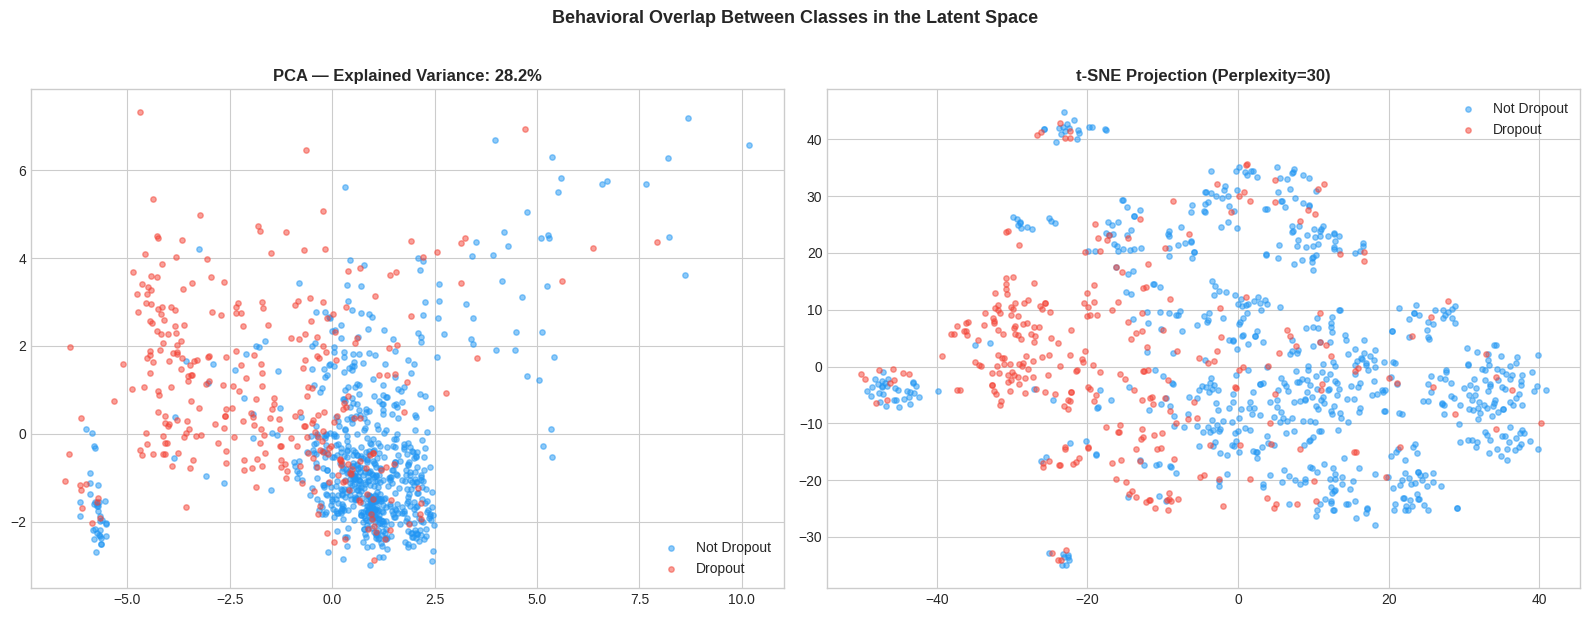

In [11]:
# %% [CELL 9] Projection and Topology of the Feature Space
if DATA_READY:
    n_viz = min(1000, X_train.shape[0])
    idx = np.random.RandomState(SEED).choice(X_train.shape[0], n_viz, replace=False)
    X_viz, y_viz = X_train[idx], y_train[idx]

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    colors = {0: '#2196F3', 1: '#F44336'}
    labels = {0: 'Not Dropout', 1: 'Dropout'}

    pca = PCA(n_components=2, random_state=SEED)
    X_pca = pca.fit_transform(X_viz)
    for cls in [0, 1]:
        m = y_viz == cls
        axes[0].scatter(X_pca[m, 0], X_pca[m, 1], c=colors[cls], label=labels[cls], alpha=0.5, s=15)
    axes[0].set_title(f'PCA — Explained Variance: {pca.explained_variance_ratio_.sum() * 100:.1f}%',
                      fontweight='bold')
    axes[0].legend()

    tsne = TSNE(n_components=2, perplexity=30, **{TSNE_ITER_KW: 1000},
                learning_rate='auto', init='pca', random_state=SEED)
    X_tsne = tsne.fit_transform(X_viz)
    for cls in [0, 1]:
        m = y_viz == cls
        axes[1].scatter(X_tsne[m, 0], X_tsne[m, 1], c=colors[cls], label=labels[cls], alpha=0.5, s=15)
    axes[1].set_title('t-SNE Projection (Perplexity=30)', fontweight='bold')
    axes[1].legend()

    plt.suptitle('Behavioral Overlap Between Classes in the Latent Space',
                 fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(caminho_saida('tsne_pca_2d.png', 'figuras'), dpi=300, bbox_inches='tight')
    plt.show()


  Model: Random Forest + SMOTE
  F1=0.8291  Recall=0.8028  Precision=0.8571  Acc=0.8938
  AUC-ROC=0.9333  AUC-PR=0.9054  Brier=0.0896
  MCC=0.7530  Kappa=0.7522  G-Mean=0.8672
  TP=228 FP=38 FN=56 TN=563  Time=65.88s


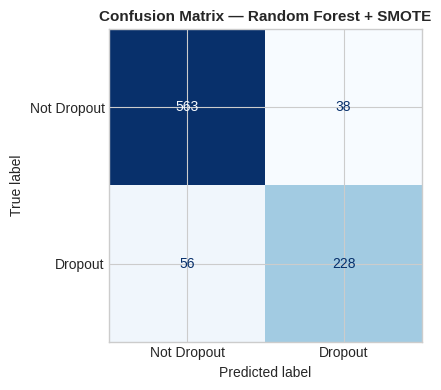


  Model: Random Forest + RandomOverSampler
  F1=0.8164  Recall=0.8063  Precision=0.8267  Acc=0.8836
  AUC-ROC=0.9330  AUC-PR=0.9034  Brier=0.0922
  MCC=0.7313  Kappa=0.7312  G-Mean=0.8614
  TP=229 FP=48 FN=55 TN=553  Time=66.51s

  Model: Random Forest + RandomUnderSampler
  F1=0.8066  Recall=0.8592  Precision=0.7601  Acc=0.8678
  AUC-ROC=0.9310  AUC-PR=0.9004  Brier=0.1034
  MCC=0.7098  Kappa=0.7068  G-Mean=0.8655
  TP=244 FP=77 FN=40 TN=524  Time=31.57s

  Model: Random Forest + NearMiss
  F1=0.7171  Recall=0.8838  Precision=0.6034  Acc=0.7763
  AUC-ROC=0.8948  AUC-PR=0.8413  Brier=0.1530
  MCC=0.5699  Kappa=0.5427  G-Mean=0.8007
  TP=251 FP=165 FN=33 TN=436  Time=34.99s

  Model: Random Forest + SMOTETomek
  F1=0.8094  Recall=0.7852  Precision=0.8352  Acc=0.8814
  AUC-ROC=0.9321  AUC-PR=0.9033  Brier=0.0908
  MCC=0.7241  Kappa=0.7234  G-Mean=0.8531
  TP=223 FP=44 FN=61 TN=557  Time=72.39s

  Model: Random Forest + SMOTEENN
  F1=0.8021  Recall=0.8204  Precision=0.7845  Acc=0.8701
  

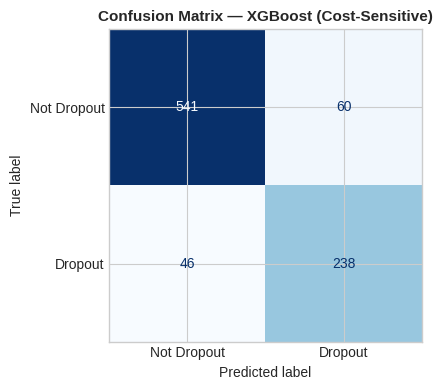

In [12]:
# %% [CELL 10] Approach 1: Supervised Modeling with Optuna and ImbPipeline
if DATA_READY:


    samplers_sup = {
        'Random Forest + SMOTE': lambda: SMOTE(random_state=SEED),
        'Random Forest + RandomOverSampler': lambda: RandomOverSampler(random_state=SEED),
        'Random Forest + RandomUnderSampler': lambda: RandomUnderSampler(random_state=SEED),
        'Random Forest + NearMiss': lambda: NearMiss(version=1),
        'Random Forest + SMOTETomek': lambda: SMOTETomek(random_state=SEED),
        'Random Forest + SMOTEENN': lambda: SMOTEENN(random_state=SEED)
    }

    for model_label, sampler_fn in samplers_sup.items():
        t0 = time.time()

        def objective_rf(trial):
            n_est = trial.suggest_int('n_estimators', 100, 400, step=50)
            m_depth = trial.suggest_int('max_depth', 5, 25)
            min_split = trial.suggest_int('min_samples_split', 2, 12)
            min_leaf = trial.suggest_int('min_samples_leaf', 1, 6)
            max_feat = trial.suggest_categorical('max_features', ['sqrt', 'log2'])

            # Pipeline encapsulating StandardScaler and resampling on training data only
            pipe = ImbPipeline([
                ('scaler', StandardScaler()),
                ('sampler', sampler_fn()),
                ('clf', RandomForestClassifier(
                    n_estimators=n_est, max_depth=m_depth,
                    min_samples_split=min_split, min_samples_leaf=min_leaf,
                    max_features=max_feat, random_state=SEED, n_jobs=N_JOBS_CV
                ))
            ])
            pipe.fit(X_train_raw.values, y_train)
            preds_val = pipe.predict(X_val_raw.values)
            return f1_score(y_val, preds_val, zero_division=0)

        study_rf = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
        study_rf.optimize(objective_rf, n_trials=N_TRIALS_SUP)
        bp = study_rf.best_params

        best_pipe = ImbPipeline([
            ('scaler', StandardScaler()),
            ('sampler', sampler_fn()),
            ('clf', RandomForestClassifier(
                n_estimators=bp['n_estimators'], max_depth=bp['max_depth'],
                min_samples_split=bp['min_samples_split'], min_samples_leaf=bp['min_samples_leaf'],
                max_features=bp['max_features'], random_state=SEED, n_jobs=N_JOBS_CV
            ))
        ])
        best_pipe.fit(X_train_raw.values, y_train)
        elapsed = time.time() - t0

        y_pred_test = best_pipe.predict(X_test_raw.values)
        y_prob_test = best_pipe.predict_proba(X_test_raw.values)[:, 1]

        models_store[model_label] = best_pipe
        met = evaluate_model(
            model_name=model_label, abordagem='Supervised',
            y_true=y_test, y_pred=y_pred_test, y_prob=y_prob_test,
            training_time=elapsed, plot_cm=(model_label == 'Random Forest + SMOTE'),
            prob_calibrated=True
        )
        if met:
            results_list.append(met)

    # --- XGBoost Baseline (Cost-Sensitive Learning via scale_pos_weight) ---
    t0 = time.time()
    base_pos_weight = float((y_train == 0).sum()) / max(1, int((y_train == 1).sum()))

    def objective_xgb(trial):
        params = {
            'n_estimators': trial.suggest_int('n_estimators', 100, 400, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 10),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.25, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_weight': trial.suggest_int('min_child_weight', 1, 8),
            'scale_pos_weight': trial.suggest_float('scale_pos_weight', base_pos_weight * 0.7, base_pos_weight * 1.5),
            'random_state': SEED,
            'eval_metric': 'logloss',
            'n_jobs': N_JOBS_CV
        }
        clf = XGBClassifier(**params)
        clf.fit(X_train, y_train)
        preds_val = clf.predict(X_val)
        return f1_score(y_val, preds_val, zero_division=0)

    study_xgb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study_xgb.optimize(objective_xgb, n_trials=N_TRIALS_SUP)
    best_xgb = XGBClassifier(**study_xgb.best_params, random_state=SEED, eval_metric='logloss', n_jobs=N_JOBS_CV)
    best_xgb.fit(X_train, y_train)
    elapsed_xgb = time.time() - t0

    y_pred_xgb = best_xgb.predict(X_test)
    y_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]
    models_store['XGBoost (Cost-Sensitive)'] = best_xgb
    met_xgb = evaluate_model(
        model_name='XGBoost (Cost-Sensitive)', abordagem='Supervised',
        y_true=y_test, y_pred=y_pred_xgb, y_prob=y_prob_xgb,
        training_time=elapsed_xgb, plot_cm=True, prob_calibrated=True
    )
    if met_xgb:
        results_list.append(met_xgb)

 Top-20 features selected: ['percentage_course_completed', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)'] ...

  Model: OC-SVM
  F1=0.7684  Recall=0.7711  Precision=0.7657  Acc=0.8508
  AUC-ROC=0.8789  AUC-PR=0.7692  Brier=-1.0000
  MCC=0.6584  Kappa=0.6584  G-Mean=0.8277
  TP=219 FP=67 FN=65 TN=534  Time=21.80s


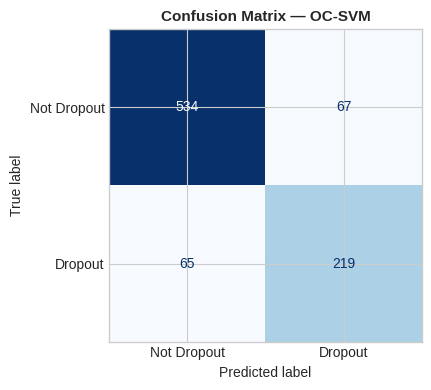


  Model: Isolation Forest
  F1=0.7267  Recall=0.7958  Precision=0.6686  Acc=0.8079
  AUC-ROC=0.8888  AUC-PR=0.8157  Brier=-1.0000
  MCC=0.5855  Kappa=0.5803  G-Mean=0.8047
  TP=226 FP=112 FN=58 TN=489  Time=43.25s


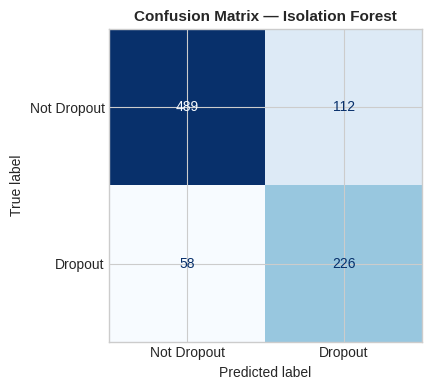


  Model: LOF
  F1=0.7296  Recall=0.6937  Precision=0.7695  Acc=0.8350
  AUC-ROC=0.8612  AUC-PR=0.7848  Brier=-1.0000
  MCC=0.6131  Kappa=0.6114  G-Mean=0.7909
  TP=197 FP=59 FN=87 TN=542  Time=17.99s

  Model: Autoencoder
  F1=0.7266  Recall=0.7254  Precision=0.7279  Acc=0.8249
  AUC-ROC=0.8713  AUC-PR=0.8149  Brier=-1.0000
  MCC=0.5978  Kappa=0.5978  G-Mean=0.7952
  TP=206 FP=77 FN=78 TN=524  Time=269.39s


In [13]:
# %% [CELL 11] Approach 2: Top-20 Feature Selection and Anomaly Detection / One-Class
if DATA_READY:


    # Top-20 feature selection fitted strictly on the training set
    rf_selector = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=N_JOBS_CV)
    rf_selector.fit(X_train, y_train)
    importances_rf = rf_selector.feature_importances_
    top20_idx = np.argsort(importances_rf)[::-1][:TOP_K_OC_FEATURES]
    top20_names = [feature_names[i] for i in top20_idx]
    print(f' Top-{TOP_K_OC_FEATURES} features selected: {top20_names[:5]} ...')

    X_train_norm_20 = X_train_normal[:, top20_idx]
    X_val_20        = X_val[:, top20_idx]
    X_test_20       = X_test[:, top20_idx]

    def optimize_dynamic_threshold(scores_val, y_val_true):
        percentis = np.linspace(5, 95, 181)
        best_th, best_f1 = np.median(scores_val), -1.0
        for q in percentis:
            th = np.percentile(scores_val, q)
            pred = (scores_val >= th).astype(int)
            f1_v = f1_score(y_val_true, pred, zero_division=0)
            if f1_v > best_f1:
                best_f1, best_th = f1_v, th
        return float(best_th), float(best_f1)

    # --- 1. One-Class SVM (OC-SVM) ---
    t0 = time.time()
    def objective_ocsvm(trial):
        kernel = trial.suggest_categorical('kernel', ['rbf', 'poly', 'sigmoid'])
        nu = trial.suggest_float('nu', 0.05, 0.50)
        gamma = trial.suggest_categorical('gamma', ['scale', 'auto'])
        oc = OneClassSVM(kernel=kernel, nu=nu, gamma=gamma)
        oc.fit(X_train_norm_20)
        s_val = -oc.decision_function(X_val_20)
        _, f1_v = optimize_dynamic_threshold(s_val, y_val)
        return f1_v

    study_ocsvm = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study_ocsvm.optimize(objective_ocsvm, n_trials=N_TRIALS_OC)
    best_ocsvm = OneClassSVM(**study_ocsvm.best_params).fit(X_train_norm_20)
    s_val_ocsvm = -best_ocsvm.decision_function(X_val_20)
    th_ocsvm, _ = optimize_dynamic_threshold(s_val_ocsvm, y_val)
    range_ocsvm = fit_score_range(s_val_ocsvm)

    s_test_ocsvm = -best_ocsvm.decision_function(X_test_20)
    y_pred_ocsvm = (s_test_ocsvm >= th_ocsvm).astype(int)
    y_prob_ocsvm = apply_score_range(s_test_ocsvm, range_ocsvm)
    elapsed_ocsvm = time.time() - t0

    models_store['OC-SVM'] = {'model': best_ocsvm, 'threshold': th_ocsvm, 'range': range_ocsvm, 'top20_idx': top20_idx}
    met_ocsvm = evaluate_model(
        model_name='OC-SVM', abordagem='One-Class',
        y_true=y_test, y_pred=y_pred_ocsvm, y_prob=y_prob_ocsvm,
        training_time=elapsed_ocsvm, plot_cm=True, prob_calibrated=False
    )
    if met_ocsvm:
        results_list.append(met_ocsvm)

    # --- 2. Isolation Forest (IF) ---
    t0 = time.time()
    def objective_if(trial):
        n_est = trial.suggest_int('n_estimators', 100, 400, step=50)
        max_samp = trial.suggest_float('max_samples', 0.4, 1.0)
        max_feat = trial.suggest_float('max_features', 0.5, 1.0)
        iso = IsolationForest(
            n_estimators=n_est, max_samples=max_samp, max_features=max_feat,
            contamination=contamination_rate, random_state=SEED, n_jobs=N_JOBS_CV
        )
        iso.fit(X_train_norm_20)
        s_val = -iso.score_samples(X_val_20)
        _, f1_v = optimize_dynamic_threshold(s_val, y_val)
        return f1_v

    study_if = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study_if.optimize(objective_if, n_trials=N_TRIALS_OC)
    best_if = IsolationForest(
        **study_if.best_params, contamination=contamination_rate, random_state=SEED, n_jobs=N_JOBS_CV
    ).fit(X_train_norm_20)
    s_val_if = -best_if.score_samples(X_val_20)
    th_if, _ = optimize_dynamic_threshold(s_val_if, y_val)
    range_if = fit_score_range(s_val_if)

    s_test_if = -best_if.score_samples(X_test_20)
    y_pred_if = (s_test_if >= th_if).astype(int)
    y_prob_if = apply_score_range(s_test_if, range_if)
    elapsed_if = time.time() - t0

    models_store['Isolation Forest'] = {'model': best_if, 'threshold': th_if, 'range': range_if, 'top20_idx': top20_idx}
    met_if = evaluate_model(
        model_name='Isolation Forest', abordagem='One-Class',
        y_true=y_test, y_pred=y_pred_if, y_prob=y_prob_if,
        training_time=elapsed_if, plot_cm=True, prob_calibrated=False
    )
    if met_if:
        results_list.append(met_if)

    # --- 3. Local Outlier Factor (LOF) ---
    t0 = time.time()
    def objective_lof(trial):
        n_neigh = trial.suggest_int('n_neighbors', 5, 50)
        metric = trial.suggest_categorical('metric', ['euclidean', 'manhattan', 'minkowski'])
        lof = LocalOutlierFactor(n_neighbors=n_neigh, metric=metric, novelty=True, n_jobs=N_JOBS_CV)
        lof.fit(X_train_norm_20)
        s_val = -lof.decision_function(X_val_20)
        _, f1_v = optimize_dynamic_threshold(s_val, y_val)
        return f1_v

    study_lof = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study_lof.optimize(objective_lof, n_trials=N_TRIALS_OC)
    best_lof = LocalOutlierFactor(**study_lof.best_params, novelty=True, n_jobs=N_JOBS_CV).fit(X_train_norm_20)
    s_val_lof = -best_lof.decision_function(X_val_20)
    th_lof, _ = optimize_dynamic_threshold(s_val_lof, y_val)
    range_lof = fit_score_range(s_val_lof)

    s_test_lof = -best_lof.decision_function(X_test_20)
    y_pred_lof = (s_test_lof >= th_lof).astype(int)
    y_prob_lof = apply_score_range(s_test_lof, range_lof)
    elapsed_lof = time.time() - t0

    models_store['LOF'] = {'model': best_lof, 'threshold': th_lof, 'range': range_lof, 'top20_idx': top20_idx}
    met_lof = evaluate_model(
        model_name='LOF', abordagem='One-Class',
        y_true=y_test, y_pred=y_pred_lof, y_prob=y_prob_lof,
        training_time=elapsed_lof, plot_cm=False, prob_calibrated=False
    )
    if met_lof:
        results_list.append(met_lof)

    # --- 4. Autoencoder (AE — Keras/TensorFlow) ---
    t0 = time.time()
    input_dim_ae = X_train_norm_20.shape[1]

    def build_autoencoder(encoding_dim=8, hidden_dim=16, dropout_rate=0.1, lr=1e-3):
        inp = Input(shape=(input_dim_ae,))
        x = Dense(hidden_dim, activation='relu')(inp)
        x = BatchNormalization()(x)
        x = Dropout(dropout_rate)(x)
        bottleneck = Dense(encoding_dim, activation='relu')(x)
        x = Dense(hidden_dim, activation='relu')(bottleneck)
        out = Dense(input_dim_ae, activation='linear')(x)
        ae = Model(inputs=inp, outputs=out)
        ae.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='mse')
        return ae

    def objective_ae(trial):
        enc_dim = trial.suggest_int('encoding_dim', 4, 12, step=2)
        hid_dim = trial.suggest_int('hidden_dim', 14, 28, step=2)
        drop = trial.suggest_float('dropout_rate', 0.0, 0.3)
        lr = trial.suggest_float('lr', 5e-4, 5e-3, log=True)
        ae = build_autoencoder(enc_dim, hid_dim, drop, lr)
        es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=0)
        ae.fit(X_train_norm_20, X_train_norm_20, validation_split=0.15,
               epochs=40, batch_size=64, callbacks=[es], verbose=0)
        rec_val = np.mean(np.square(X_val_20 - ae.predict(X_val_20, verbose=0)), axis=1)
        _, f1_v = optimize_dynamic_threshold(rec_val, y_val)
        return f1_v

    study_ae = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study_ae.optimize(objective_ae, n_trials=N_TRIALS_AE)
    bp_ae = study_ae.best_params

    best_ae = build_autoencoder(bp_ae['encoding_dim'], bp_ae['hidden_dim'], bp_ae['dropout_rate'], bp_ae['lr'])
    es_final = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=0)
    rlrop = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, verbose=0)
    best_ae.fit(X_train_norm_20, X_train_norm_20, validation_split=0.15,
                epochs=60, batch_size=64, callbacks=[es_final, rlrop], verbose=0)

    s_val_ae = np.mean(np.square(X_val_20 - best_ae.predict(X_val_20, verbose=0)), axis=1)
    th_ae, _ = optimize_dynamic_threshold(s_val_ae, y_val)
    range_ae = fit_score_range(s_val_ae)

    s_test_ae = np.mean(np.square(X_test_20 - best_ae.predict(X_test_20, verbose=0)), axis=1)
    y_pred_ae = (s_test_ae >= th_ae).astype(int)
    y_prob_ae = apply_score_range(s_test_ae, range_ae)
    elapsed_ae = time.time() - t0

    models_store['Autoencoder'] = {'model': best_ae, 'threshold': th_ae, 'range': range_ae, 'top20_idx': top20_idx}
    met_ae = evaluate_model(
        model_name='Autoencoder', abordagem='One-Class',
        y_true=y_test, y_pred=y_pred_ae, y_prob=y_prob_ae,
        training_time=elapsed_ae, plot_cm=False, prob_calibrated=False
    )
    if met_ae:
        results_list.append(met_ae)


=== TABLE 3: Summary of Performance Metrics on the Test Set ===


,Model,Approach,F1-Score,Recall,Precision,Accuracy,BalancedAcc,Specificity,G-Mean,MCC,Kappa,AUC-ROC,AUC-PR,Brier,LogLoss,Training Time,TP,FP,FN,TN
0,Random Forest + SMOTE,Supervised,0.8291,0.8028,0.8571,0.8938,0.8698,0.9368,0.8672,0.7530,0.7522,0.9333,0.9054,0.0896,0.3046,65.8800,228,38,56,563
1,Random Forest + RandomOverSampler,Supervised,0.8164,0.8063,0.8267,0.8836,0.8632,0.9201,0.8614,0.7313,0.7312,0.9330,0.9034,0.0922,0.3110,66.5100,229,48,55,553
2,XGBoost (Cost-Sensitive),Supervised,0.8179,0.8380,0.7987,0.8802,0.8691,0.9002,0.8685,0.7292,0.7287,0.9355,0.9104,0.0945,0.3225,14.3000,238,60,46,541
3,Random Forest + SMOTETomek,Supervised,0.8094,0.7852,0.8352,0.8814,0.8560,0.9268,0.8531,0.7241,0.7234,0.9321,0.9033,0.0908,0.3071,72.3900,223,44,61,557
4,Random Forest + RandomUnderSampler,Supervised,0.8066,0.8592,0.7601,0.8678,0.8655,0.8719,0.8655,0.7098,0.7068,0.9310,0.9004,0.1034,0.3429,31.5700,244,77,40,524
5,Random Forest + SMOTEENN,Supervised,0.8021,0.8204,0.7845,0.8701,0.8570,0.8935,0.8562,0.7058,0.7054,0.9244,0.8872,0.0986,0.3264,51.9100,233,64,51,537
6,OC-SVM,One-Class,0.7684,0.7711,0.7657,0.8508,0.8298,0.8885,0.8277,0.6584,0.6584,0.8789,0.7692,NaN,NaN,21.8000,219,67,65,534
7,LOF,One-Class,0.7296,0.6937,0.7695,0.8350,0.7977,0.9018,0.7909,0.6131,0.6114,0.8612,0.7848,NaN,NaN,17.9900,197,59,87,542
8,Autoencoder,One-Class,0.7266,0.7254,0.7279,0.8249,0.7986,0.8719,0.7952,0.5978,0.5978,0.8713,0.8149,NaN,NaN,269.3900,206,77,78,524
9,Isolation Forest,One-Class,0.7267,0.7958,0.6686,0.8079,0.8047,0.8136,0.8047,0.5855,0.5803,0.8888,0.8157,NaN,NaN,43.2500,226,112,58,489


🏆 Best Supervised (MCC): Random Forest + SMOTE
🏆 Best One-Class      (MCC): OC-SVM

--- Ablation Study: Impact of percentage_course_completed (Multi-Seed) ---


,Scenario,MCC (Mean ± SD),F1-Score (Mean ± SD)
0,With Synthetic Feature (35 attr.),0.7280 ± 0.0038,0.8171 ± 0.0025
1,Without Synthetic Feature (34 attr.),0.7427 ± 0.0055,0.8248 ± 0.0035


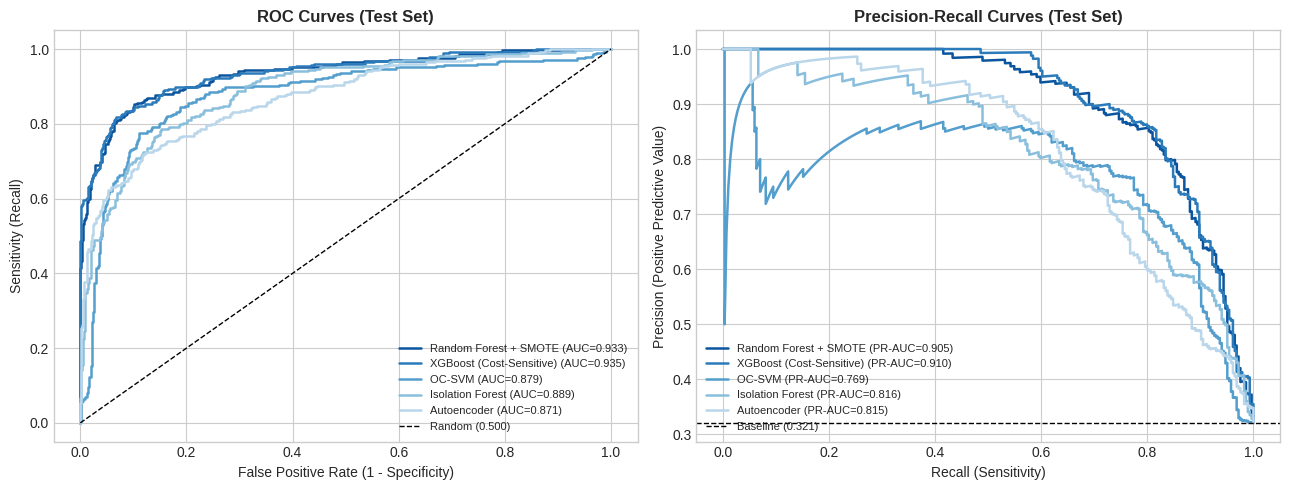

In [14]:
# %% [CELL 12] Table 3 Consolidation, Ablation Study and ROC + PR Curves
if DATA_READY and len(results_list) > 0:
    df_results = pd.DataFrame(results_list).sort_values(by=METRICA_REFERENCIA, ascending=False).reset_index(drop=True)
    print('\n=== TABLE 3: Summary of Performance Metrics on the Test Set ===')
    display(df_results)
    df_results.to_csv(caminho_saida('tabela3_desempenho_modelos.csv', 'tabelas'), index=False)

    # Identify the champions of each paradigm by MCC
    best_sup_name = df_results[df_results['Approach'] == 'Supervised'].iloc[0]['Model']
    best_oc_name  = df_results[df_results['Approach'] == 'One-Class'].iloc[0]['Model']
    print(f'🏆 Best Supervised ({METRICA_REFERENCIA}): {best_sup_name}')
    print(f'🏆 Best One-Class      ({METRICA_REFERENCIA}): {best_oc_name}')

    # --- Run Ablation Study of the Synthetic Variable 'percentage_course_completed' ---
    print('\n--- Ablation Study: Impact of percentage_course_completed (Multi-Seed) ---')
    df_ablacao = ablation_feature_sintetica(
        model_builder_fn=lambda s: XGBClassifier(
            **study_xgb.best_params, random_state=s, eval_metric='logloss', n_jobs=N_JOBS_CV
        ),
        X_tr=X_train, y_tr=y_train, X_te=X_test, y_te=y_test,
        feature_names=feature_names, seeds=SEEDS_ABLACAO
    )

    # --- Plot ROC and Precision-Recall Curves Side by Side ---
    modelos_destaque = [best_sup_name, 'XGBoost (Cost-Sensitive)', best_oc_name, 'Isolation Forest', 'Autoencoder']
    modelos_destaque = list(dict.fromkeys([m for m in modelos_destaque if m in preds_store]))
    plot_roc_and_pr_curves(y_test, modelos_destaque, fname='roc_pr_comparativo.png')


=== Running Paired Bootstrap (2000 iterations) ===


,Model,MCC_mean,MCC_CI95,F1_mean,F1_CI95,Recall_mean,Recall_CI95,Specificity_mean,Specificity_CI95,AUC-ROC_mean,AUC-ROC_CI95
0,Random Forest + SMOTE,0.7533,[0.7037; 0.7988],0.8290,[0.7934; 0.8618],0.8027,[0.7553; 0.8481],0.9370,[0.9169; 0.9554],0.9332,[0.9122; 0.9517]
1,Random Forest + RandomOverSampler,0.7316,[0.6808; 0.7804],0.8164,[0.7799; 0.8513],0.8064,[0.7584; 0.8516],0.9203,[0.8986; 0.9408],0.9329,[0.9122; 0.9514]
2,Random Forest + RandomUnderSampler,0.7103,[0.6615; 0.7604],0.8068,[0.7705; 0.8416],0.8596,[0.8175; 0.8990],0.8720,[0.8458; 0.8982],0.9310,[0.9102; 0.9499]
3,Random Forest + NearMiss,0.5698,[0.5174; 0.6221],0.7170,[0.6784; 0.7557],0.8836,[0.8462; 0.9207],0.7256,[0.6876; 0.7628],0.8946,[0.8714; 0.9174]
4,Random Forest + SMOTETomek,0.7241,[0.6751; 0.7723],0.8092,[0.7737; 0.8444],0.7849,[0.7368; 0.8315],0.9269,[0.9054; 0.9468],0.9321,[0.9113; 0.9509]
5,Random Forest + SMOTEENN,0.7060,[0.6564; 0.7555],0.8020,[0.7650; 0.8374],0.8204,[0.7754; 0.8635],0.8937,[0.8693; 0.9175],0.9243,[0.9023; 0.9439]
6,XGBoost (Cost-Sensitive),0.7295,[0.6810; 0.7762],0.8179,[0.7835; 0.8499],0.8379,[0.7933; 0.8799],0.9005,[0.8769; 0.9237],0.9354,[0.9158; 0.9542]
7,OC-SVM,0.6583,[0.6048; 0.7093],0.7680,[0.7273; 0.8049],0.7708,[0.7218; 0.8192],0.8886,[0.8636; 0.9135],0.8792,[0.8495; 0.9052]
8,Isolation Forest,0.5858,[0.5305; 0.6411],0.7266,[0.6867; 0.7664],0.7961,[0.7500; 0.8431],0.8135,[0.7812; 0.8456],0.8887,[0.8635; 0.9120]
9,LOF,0.6128,[0.5566; 0.6673],0.7292,[0.6857; 0.7685],0.6935,[0.6391; 0.7444],0.9017,[0.8772; 0.9240],0.8612,[0.8332; 0.8890]


 Δ MCC (Random Forest + SMOTE vs OC-SVM): 0.0950 95% CI [0.0521; 0.1380] | p-value = 9.9950e-04
 Δ MCC (XGBoost (Cost-Sensitive) vs OC-SVM): 0.0713 95% CI [0.0249; 0.1191] | p-value = 1.9990e-03

=== DeLong Test (ROC Curve Comparison) ===


,Model A,Model B,AUC A,AUC B,Delta AUC,Z-stat,p-value (two-sided)
0,Random Forest + SMOTE,OC-SVM,0.9333,0.8789,0.0543,5.0419,0.0000
1,Random Forest + SMOTE,Isolation Forest,0.9333,0.8888,0.0445,4.7004,0.0000
2,Random Forest + SMOTE,Autoencoder,0.9333,0.8713,0.0620,5.5730,0.0000
3,XGBoost (Cost-Sensitive),OC-SVM,0.9355,0.8789,0.0565,5.3919,0.0000
4,XGBoost (Cost-Sensitive),Isolation Forest,0.9355,0.8888,0.0467,4.7790,0.0000
5,XGBoost (Cost-Sensitive),Autoencoder,0.9355,0.8713,0.0642,5.5407,0.0000



=== Paired McNemar Test with Holm-Bonferroni Correction ===


,Model 1,Model 2,McNemar Statistic,p_raw,p_Holm_Bonferroni
0,Random Forest + SMOTE,XGBoost (Cost-Sensitive),3.7812,0.0518,0.1527
1,Random Forest + SMOTE,OC-SVM,16.2976,0.0001,0.0004
2,Random Forest + SMOTE,Isolation Forest,41.9776,0.0000,0.0000
3,Random Forest + SMOTE,Autoencoder,27.0677,0.0000,0.0000
4,XGBoost (Cost-Sensitive),OC-SVM,6.2500,0.0124,0.0497
5,XGBoost (Cost-Sensitive),Isolation Forest,27.5625,0.0000,0.0000
6,XGBoost (Cost-Sensitive),Autoencoder,15.2583,0.0001,0.0005
7,OC-SVM,Isolation Forest,15.9186,0.0001,0.0004
8,OC-SVM,Autoencoder,3.8110,0.0509,0.1527
9,Isolation Forest,Autoencoder,1.5433,0.2141,0.2141



=== Expected Calibration Error (ECE) ===
  XGBoost (Cost-Sensitive)       | ECE = 0.1008
  Random Forest + SMOTE          | ECE = 0.0686
  OC-SVM                         | ECE = 0.2355
  Isolation Forest               | ECE = 0.0684


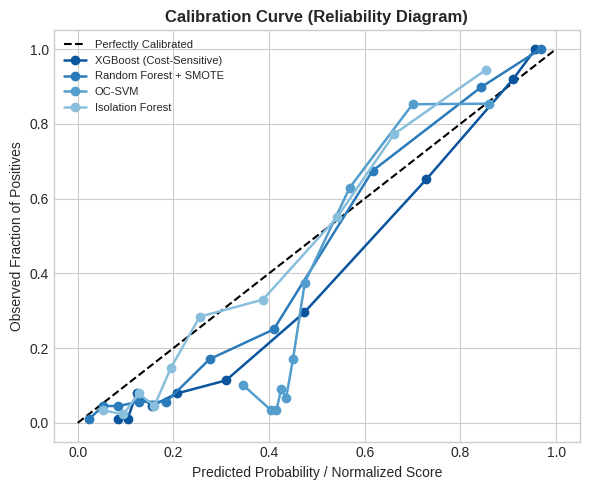

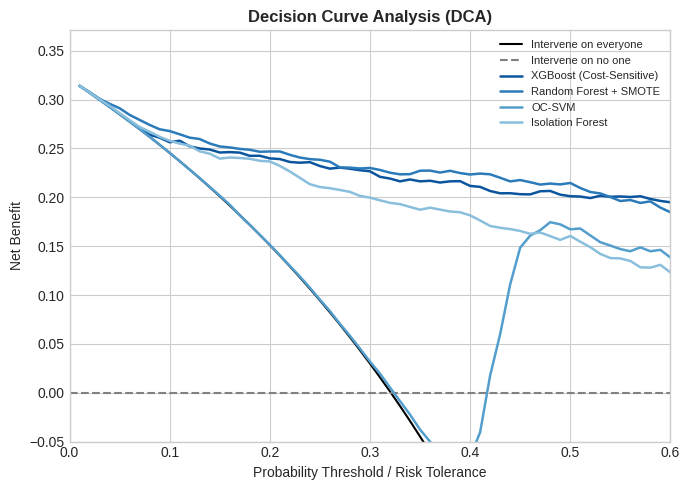

In [15]:
# %% [CELL 13] Statistical Rigor (Paired Bootstrap, DeLong, McNemar-Holm) and Practical Utility
if DATA_READY and len(preds_store) > 0:
    print(f'=== Running Paired Bootstrap ({N_BOOT} iterations) ===')
    boot_results = paired_bootstrap(y_test, preds_store, n_boot=N_BOOT, seed=SEED)

    boot_rows = []
    for m_name, metrics_dict in boot_results.items():
        row = {'Model': m_name}
        for met_k in ['MCC', 'F1', 'Recall', 'Specificity', 'AUC-ROC']:
            if met_k in metrics_dict:
                mean_v, lo_v, hi_v = summarize_bootstrap(metrics_dict[met_k])
                row[f'{met_k}_mean'] = round(mean_v, 4)
                row[f'{met_k}_CI95'] = f'[{lo_v:.4f}; {hi_v:.4f}]'
        boot_rows.append(row)
    df_boot = pd.DataFrame(boot_rows)
    display(df_boot)
    df_boot.to_csv(caminho_saida('bootstrap_ic95.csv', 'tabelas'), index=False)

    # Paired MCC difference between Supervised and Best One-Class
    for ref_sup in [best_sup_name, 'XGBoost (Cost-Sensitive)']:
        if ref_sup in boot_results and best_oc_name in boot_results:
            delta_mcc = boot_results[ref_sup]['MCC'] - boot_results[best_oc_name]['MCC']
            d_mean, d_lo, d_hi = summarize_bootstrap(delta_mcc)
            p_boot = paired_delta_pvalue(delta_mcc)
            print(f' Δ MCC ({ref_sup} vs {best_oc_name}): {d_mean:.4f} 95% CI [{d_lo:.4f}; {d_hi:.4f}] | p-value = {p_boot:.4e}')

    # --- Nonparametric DeLong Test (AUC-ROC) ---
    print('\n=== DeLong Test (ROC Curve Comparison) ===')
    delong_rows = []
    for ref_sup in [best_sup_name, 'XGBoost (Cost-Sensitive)']:
        for oc_m in ['OC-SVM', 'Isolation Forest', 'Autoencoder']:
            if ref_sup in preds_store and oc_m in preds_store:
                auc1, auc2, z_stat, p_delong = delong_test(
                    y_test, preds_store[ref_sup]['y_prob'], preds_store[oc_m]['y_prob']
                )
                delong_rows.append({
                    'Model A': ref_sup, 'Model B': oc_m,
                    'AUC A': round(auc1, 4), 'AUC B': round(auc2, 4),
                    'Delta AUC': round(auc1 - auc2, 4), 'Z-stat': round(z_stat, 4),
                    'p-value (two-sided)': p_delong
                })
    df_delong = pd.DataFrame(delong_rows).drop_duplicates()
    display(df_delong)
    df_delong.to_csv(caminho_saida('teste_delong_auc.csv', 'tabelas'), index=False)

    # --- McNemar test with Holm-Bonferroni correction ---
    print('\n=== Paired McNemar Test with Holm-Bonferroni Correction ===')
    pares_mcnemar = []
    for m1, m2 in combinations(modelos_destaque, 2):
        stat_mc, p_mc = mcnemar_test(y_test, preds_store[m1]['y_pred'], preds_store[m2]['y_pred'])
        pares_mcnemar.append({'Model 1': m1, 'Model 2': m2, 'McNemar Statistic': round(stat_mc, 4), 'p_raw': p_mc})
    df_mcnemar = pd.DataFrame(pares_mcnemar)
    df_mcnemar['p_Holm_Bonferroni'] = holm_correction(df_mcnemar['p_raw'].values)
    display(df_mcnemar)
    df_mcnemar.to_csv(caminho_saida('teste_mcnemar_holm.csv', 'tabelas'), index=False)

    # --- FIGURE 5 (Calibration Curve + ECE) and FIGURE 6 (Decision Curve Analysis - DCA) ---
    modelos_curvas = ['XGBoost (Cost-Sensitive)', best_sup_name, 'OC-SVM', 'Isolation Forest']
    modelos_curvas = list(dict.fromkeys([m for m in modelos_curvas if m in preds_store]))
    probs_curvas = [preds_store[m]['y_prob'] for m in modelos_curvas]

    print('\n=== Expected Calibration Error (ECE) ===')
    for m_c, p_c in zip(modelos_curvas, probs_curvas):
        print(f'  {m_c:30s} | ECE = {compute_ece(y_test, p_c):.4f}')

    calibration_plot(y_test, probs_curvas, modelos_curvas, n_bins=10, fname='calibracao.png')
    decision_curve_analysis(y_test, probs_curvas, modelos_curvas, fname='dca.png')

=== Global XAI Audit: SHAP TreeExplainer (Supervised vs. One-Class) ===


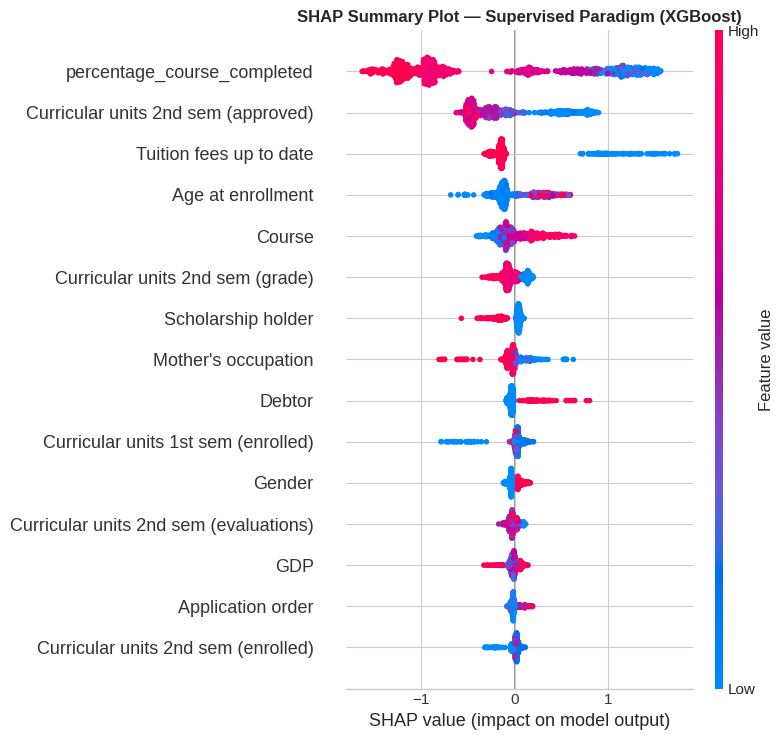

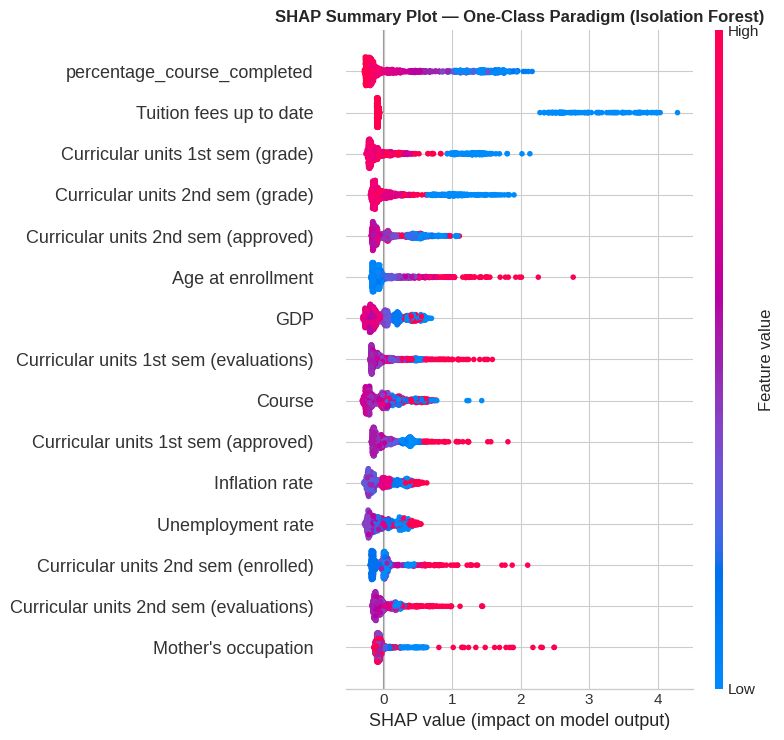


 Spearman Rank Correlation (Common Features N=20):
  ρ (rho) = 0.5940 | p-value = 0.0058


,Feature,Mean_Abs_SHAP_Supervised,Mean_Abs_SHAP_OneClass,Rank_Supervised,Rank_OneClass
0,percentage_course_completed,0.9915,0.5199,1.0000,1.0000
1,Curricular units 2nd sem (approved),0.3973,0.2431,2.0000,5.0000
5,Tuition fees up to date,0.2857,0.4676,3.0000,2.0000
6,Age at enrollment,0.1902,0.2272,4.0000,6.0000
7,Course,0.1482,0.2038,5.0000,9.0000
2,Curricular units 2nd sem (grade),0.0893,0.3044,6.0000,4.0000
11,Mother's occupation,0.0708,0.1304,7.0000,15.0000
14,Curricular units 1st sem (enrolled),0.0582,0.1278,8.0000,17.0000
8,Curricular units 2nd sem (evaluations),0.0350,0.1496,9.0000,14.0000
17,GDP,0.0346,0.2107,10.0000,7.0000


In [16]:
# %% [CELL 14] Global XAI Audit
if DATA_READY and 'XGBoost (Cost-Sensitive)' in models_store and 'Isolation Forest' in models_store:
    print('=== Global XAI Audit: SHAP TreeExplainer (Supervised vs. One-Class) ===')

    xgb_audit = models_store['XGBoost (Cost-Sensitive)']
    if_audit  = models_store['Isolation Forest']['model']
    top20_idx_audit = models_store['Isolation Forest']['top20_idx']
    top20_names_audit = [feature_names[i] for i in top20_idx_audit]

    # 1. Global SHAP — Supervised Model (XGBoost)
    explainer_xgb = shap.TreeExplainer(xgb_audit)
    shap_values_xgb = explainer_xgb.shap_values(X_test)
    if isinstance(shap_values_xgb, list):
        shap_values_xgb = shap_values_xgb[1]

    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values_xgb, X_test, feature_names=feature_names, max_display=15, show=False)
    plt.title('SHAP Summary Plot — Supervised Paradigm (XGBoost)', fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.savefig(caminho_saida('shap_summary_supervisionado.png', 'figuras'), dpi=200, bbox_inches='tight')
    plt.show()

    # 2. Global SHAP — One-Class Model (Isolation Forest)
    # Flipping the sign (-shap_values) so that positive values push toward Anomaly/Dropout
    explainer_if = shap.TreeExplainer(if_audit)
    shap_values_if = -explainer_if.shap_values(X_test[:, top20_idx_audit])
    if isinstance(shap_values_if, list):
        shap_values_if = -shap_values_if[0]

    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values_if, X_test[:, top20_idx_audit], feature_names=top20_names_audit, max_display=15, show=False)
    plt.title('SHAP Summary Plot — One-Class Paradigm (Isolation Forest)', fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.savefig(caminho_saida('shap_summary_oneclass.png', 'figuras'), dpi=200, bbox_inches='tight')
    plt.show()

    # 3. Spearman Rank Correlation over the Common Features (Section 4.4)
    mean_abs_shap_xgb_common = np.abs(shap_values_xgb[:, top20_idx_audit]).mean(axis=0)
    mean_abs_shap_if_common  = np.abs(shap_values_if).mean(axis=0)

    rho_spearman, p_spearman = stats.spearmanr(mean_abs_shap_xgb_common, mean_abs_shap_if_common)
    print(f'\n Spearman Rank Correlation (Common Features N={len(top20_idx_audit)}):')
    print(f'  ρ (rho) = {rho_spearman:.4f} | p-value = {p_spearman:.4f}')

    df_shap_comp = pd.DataFrame({
        'Feature': top20_names_audit,
        'Mean_Abs_SHAP_Supervised': mean_abs_shap_xgb_common,
        'Mean_Abs_SHAP_OneClass': mean_abs_shap_if_common,
        'Rank_Supervised': stats.rankdata(-mean_abs_shap_xgb_common),
        'Rank_OneClass': stats.rankdata(-mean_abs_shap_if_common)
    }).sort_values(by='Rank_Supervised')
    display(df_shap_comp.head(10))
    df_shap_comp.to_csv(caminho_saida('shap_spearman_concordancia.csv', 'tabelas'), index=False)

=== Local XAI Audit: Multi-Seed LIME Stability and Jaccard Index ===
 Evaluating 50 True Positive students across 5 seeds ([42, 43, 44, 45, 46])...


,Seed,Jaccard_Mean_Sup_vs_OneClass,Jaccard_SD,Baseline_Random
0,42,0.3444,0.0879,0.1862
1,43,0.3472,0.1071,0.1756
2,44,0.3232,0.0856,0.1662
3,45,0.3362,0.0922,0.1824
4,46,0.3454,0.0959,0.1755


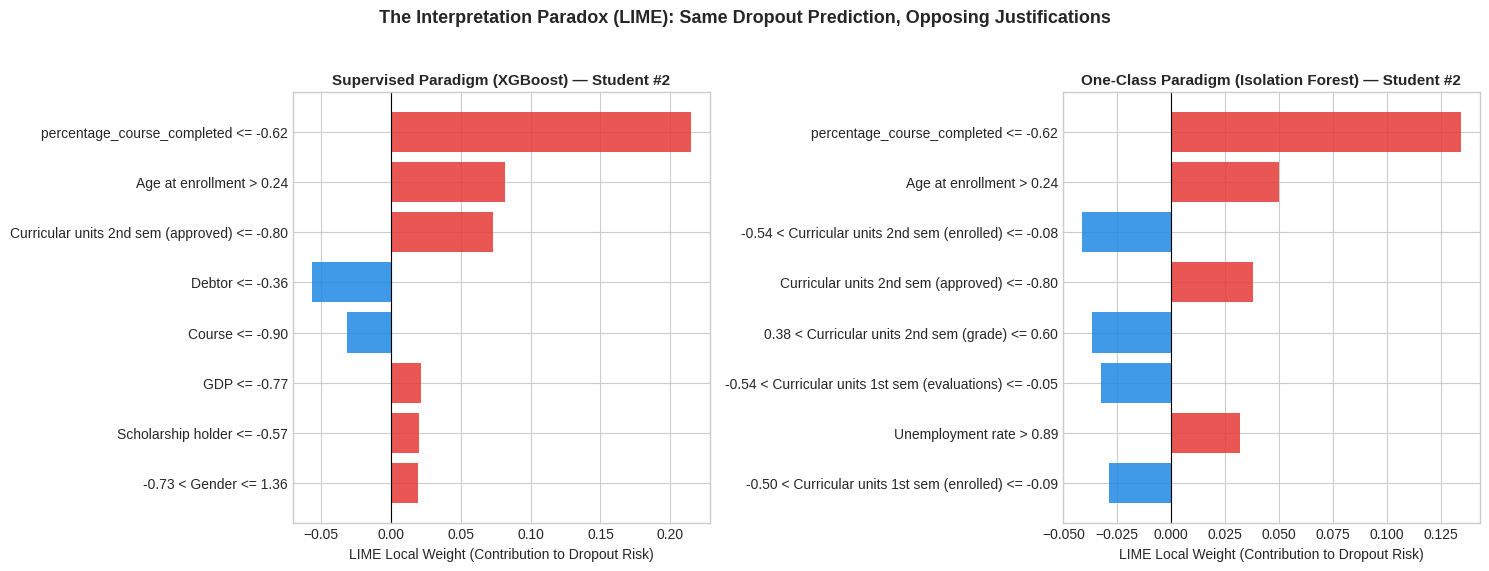

In [17]:
# %% [CELL 15] The Local Interpretation Paradox
if DATA_READY and 'XGBoost (Cost-Sensitive)' in models_store and 'Isolation Forest' in models_store:
    print('=== Local XAI Audit: Multi-Seed LIME Stability and Jaccard Index ===')

    xgb_audit = models_store['XGBoost (Cost-Sensitive)']
    if_dict   = models_store['Isolation Forest']
    if_audit  = if_dict['model']
    range_if  = if_dict['range']
    top20_idx_audit = if_dict['top20_idx']

    # Wrapper that projects the 35 features onto the Isolation Forest's Top-20 subspace and returns probabilities [P(Normal), P(Anomaly)]
    def predict_proba_if_full(X_input):
        X_arr = np.asarray(X_input, dtype=float)
        scores_anom = -if_audit.score_samples(X_arr[:, top20_idx_audit])
        p_anom = apply_score_range(scores_anom, range_if)
        return np.column_stack([1.0 - p_anom, p_anom])

    # Select True Positive students for whom BOTH paradigms agree on dropout
    mask_tp_ambos = (y_test == 1) & (preds_store['XGBoost (Cost-Sensitive)']['y_pred'] == 1) & (preds_store['Isolation Forest']['y_pred'] == 1)
    idx_tp_ambos = np.where(mask_tp_ambos)[0]
    if len(idx_tp_ambos) == 0:
        idx_tp_ambos = np.where(y_test == 1)[0]

    n_amostras_lime = min(N_LIME_SAMPLES_R, len(idx_tp_ambos))
    amostras_audit = idx_tp_ambos[:n_amostras_lime]
    print(f' Evaluating {n_amostras_lime} True Positive students across {N_LIME_SEEDS} seeds ({SEEDS_LIME})...')

    jaccard_por_seed = []
    rng_base = np.random.RandomState(SEED)

    for s_lime in SEEDS_LIME:
        explainer_lime = LimeTabularExplainer(
            training_data=X_train,
            feature_names=feature_names,
            class_names=['Not Dropout', 'Dropout'],
            mode='classification',
            random_state=s_lime
        )
        jaccards_amostras = []
        jaccards_random   = []

        for idx_aluno in amostras_audit:
            x_inst = X_test[idx_aluno]
            exp_sup = explainer_lime.explain_instance(
                x_inst, xgb_audit.predict_proba, num_features=XAI_K_TOP, num_samples=N_LIME_SAMPLES
            )
            exp_occ = explainer_lime.explain_instance(
                x_inst, predict_proba_if_full, num_features=XAI_K_TOP, num_samples=N_LIME_SAMPLES
            )
            # Exact extraction by indices via as_map() per Section 3.6
            top_sup_set = set([feat_idx for feat_idx, _ in exp_sup.as_map()[1][:XAI_K_TOP]])
            top_occ_set = set([feat_idx for feat_idx, _ in exp_occ.as_map()[1][:XAI_K_TOP]])

            inter = len(top_sup_set & top_occ_set)
            union = len(top_sup_set | top_occ_set)
            jaccards_amostras.append(inter / union if union > 0 else 0.0)

            # Paired random baseline (draw without replacement of K features out of 35)
            rnd_a = set(rng_base.choice(len(feature_names), XAI_K_TOP, replace=False))
            rnd_b = set(rng_base.choice(len(feature_names), XAI_K_TOP, replace=False))
            jaccards_random.append(len(rnd_a & rnd_b) / len(rnd_a | rnd_b))

        jaccard_por_seed.append({
            'Seed': s_lime,
            'Jaccard_Mean_Sup_vs_OneClass': round(float(np.mean(jaccards_amostras)), 4),
            'Jaccard_SD': round(float(np.std(jaccards_amostras)), 4),
            'Baseline_Random': round(float(np.mean(jaccards_random)), 4)
        })

    df_lime_jaccard = pd.DataFrame(jaccard_por_seed)
    display(df_lime_jaccard)
    df_lime_jaccard.to_csv(caminho_saida('lime_jaccard_multiseed.csv', 'tabelas'), index=False)

    # --- FIGURE 9: The Local Interpretation Paradox in a True Positive Student (Student X) ---
    # Preferably look for a profile with socioeconomic vulnerability (e.g., Debtor=1 or Age>=24) among the common TPs
    idx_aluno_x = amostras_audit[0]
    for cand_idx in idx_tp_ambos:
        row_raw = X_test_raw.iloc[cand_idx]
        if row_raw.get('Debtor', 0) == 1 or row_raw.get('Scholarship holder', 1) == 0:
            idx_aluno_x = cand_idx
            break

    explainer_fig9 = LimeTabularExplainer(
        training_data=X_train, feature_names=feature_names,
        class_names=['Not Dropout', 'Dropout'], mode='classification', random_state=SEED
    )
    exp_sup_x = explainer_fig9.explain_instance(X_test[idx_aluno_x], xgb_audit.predict_proba, num_features=8, num_samples=N_LIME_SAMPLES)
    exp_occ_x = explainer_fig9.explain_instance(X_test[idx_aluno_x], predict_proba_if_full, num_features=8, num_samples=N_LIME_SAMPLES)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    for ax, exp_obj, titulo in [
        (axes[0], exp_sup_x, f'Supervised Paradigm (XGBoost) — Student #{idx_aluno_x}'),
        (axes[1], exp_occ_x, f'One-Class Paradigm (Isolation Forest) — Student #{idx_aluno_x}')
    ]:
        lista_exp = exp_obj.as_list(label=1)[::-1]
        nomes_f = [item[0] for item in lista_exp]
        pesos_f = [item[1] for item in lista_exp]
        cores_f = ['#E53935' if w > 0 else '#1E88E5' for w in pesos_f]
        ax.barh(nomes_f, pesos_f, color=cores_f, alpha=0.85)
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set_title(titulo, fontweight='bold', fontsize=11)
        ax.set_xlabel('LIME Local Weight (Contribution to Dropout Risk)')

    plt.suptitle('The Interpretation Paradox (LIME): Same Dropout Prediction, Opposing Justifications',
                 fontsize=13, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.savefig(caminho_saida('lime_paradoxo_interpretacao_alunoX.png', 'figuras'), dpi=250, bbox_inches='tight')
    plt.show()


In [18]:

# %% [CELL 16] Fairness Audit and Two-Layer Hybrid System
if DATA_READY and len(preds_store) > 0:
    print('=== Section 5.2: Algorithmic Fairness Audit and Disparate Impact ===')
    modelos_auditoria = [best_sup_name, 'XGBoost (Cost-Sensitive)', best_oc_name, 'Isolation Forest']
    modelos_auditoria = list(dict.fromkeys([m for m in modelos_auditoria if m in preds_store]))

    df_fairness = fairness_audit(
        X_test_raw_df=X_test_raw,
        y_true=y_test,
        preds_store=preds_store,
        model_names=modelos_auditoria
    )

    print('\n=== Section 6: Operational Simulation of the Complementary Two-Layer System ===')
    df_duas_camadas = simular_sistema_duas_camadas(
        y_true=y_test,
        pred_sup=preds_store[best_sup_name]['y_pred'],
        pred_occ=preds_store['Isolation Forest']['y_pred'],
        nome_sup=best_sup_name,
        nome_occ='Isolation Forest'
    )

=== Section 5.2: Algorithmic Fairness Audit and Disparate Impact ===


,Demographic / Social Group,Model,Selection Rate (Vulnerable),Selection Rate (Reference),Disparate Impact Ratio,FPR (Vulnerable),FPR (Reference),FPR Difference (Stigma)
0,Gender (Male=1 vs Female=0),Random Forest + SMOTE,0.4424,0.2199,2.0121,0.1257,0.0376,0.0882
1,Gender (Male=1 vs Female=0),XGBoost (Cost-Sensitive),0.4922,0.2482,1.9829,0.1943,0.0610,0.1333
2,Gender (Male=1 vs Female=0),OC-SVM,0.4393,0.2571,1.7085,0.1486,0.0962,0.0523
3,Gender (Male=1 vs Female=0),Isolation Forest,0.5016,0.3138,1.5982,0.2514,0.1596,0.0918
4,Debtor (Defaulter=1 vs Up to date=0),Random Forest + SMOTE,0.5889,0.2679,2.1980,0.1316,0.0586,0.0730
5,Debtor (Defaulter=1 vs Up to date=0),XGBoost (Cost-Sensitive),0.6556,0.3006,2.1806,0.2368,0.0906,0.1463
6,Debtor (Defaulter=1 vs Up to date=0),OC-SVM,0.7556,0.2742,2.7554,0.5263,0.0835,0.4428
7,Debtor (Defaulter=1 vs Up to date=0),Isolation Forest,0.8333,0.3308,2.5190,0.6316,0.1563,0.4753
8,Scholarship (No Scholarship=0 vs Holder=1),Random Forest + SMOTE,0.3746,0.0909,4.1208,0.0877,0.0149,0.0729
9,Scholarship (No Scholarship=0 vs Holder=1),XGBoost (Cost-Sensitive),0.4190,0.1039,4.0325,0.1353,0.0297,0.1056



=== Section 6: Operational Simulation of the Complementary Two-Layer System ===


,Intervention Quadrant,Total Students (Test),% of Cohort,Actual Dropouts Captured,Actual Dropout Rate in Group (%)
0,Q1: Double Risk (Tutoring + Social Assistance),235,26.6000,209,88.9000
1,Q2: Pure Academic Risk (Focus on Tutoring/Peer...,31,3.5000,19,61.3000
2,Q3: Silent Structural Vulnerability (Social Ra...,103,11.6000,17,16.5000
3,Q4: Low Overall Risk (Regular Follow-up),516,58.3000,39,7.6000


In [19]:
print(modelos_destaque)
print('Criterion in the code: [best supervised by MCC, XGBoost, best OCC by MCC, Isolation Forest, Autoencoder]')
print('LOF was left out because it is not in the list; Isolation Forest and Autoencoder were fixed manually.')

print('\n=== ITEM 2: the 20 subspace variables (selected by RF importance on the training set) ===')
top20_names_chk = [feature_names[i] for i in top20_idx]
for r, n in enumerate(top20_names_chk, 1):
    print(f'{r:2d}. {n}')
for v in ['Scholarship holder', 'Debtor', 'Gender']:
    print(f'{v!r:24s} within the 20? {v in top20_names_chk}')
print('\nSHAP ranking of the Isolation Forest among the 20 (Rank_OneClass):')
display(df_shap_comp.sort_values('Rank_OneClass')[['Feature', 'Rank_OneClass', 'Rank_Supervised']])

print('\n=== ITEM 6: categorical encoding ===')
cat_cands = ['Course', 'Nacionality', 'Nationality', 'Application mode', "Mother's occupation", "Father's occupation"]
for c in cat_cands:
    if c in X_train_raw.columns:
        print(f'{c:22s} dtype={X_train_raw[c].dtype} | distinct={X_train_raw[c].nunique()} | '
              f'min={X_train_raw[c].min()} max={X_train_raw[c].max()}')
print('Object columns (would go through LabelEncoder):', [c for c in preprocessor.df.columns if preprocessor.df[c].dtype == "object"])
print('Scaler:', type(scaler).__name__, '| fitted on the training set only (see split_and_scale).')


['Random Forest + SMOTE', 'XGBoost (Cost-Sensitive)', 'OC-SVM', 'Isolation Forest', 'Autoencoder']
Criterion in the code: [best supervised by MCC, XGBoost, best OCC by MCC, Isolation Forest, Autoencoder]
LOF was left out because it is not in the list; Isolation Forest and Autoencoder were fixed manually.

=== ITEM 2: the 20 subspace variables (selected by RF importance on the training set) ===
 1. percentage_course_completed
 2. Curricular units 2nd sem (approved)
 3. Curricular units 2nd sem (grade)
 4. Curricular units 1st sem (approved)
 5. Curricular units 1st sem (grade)
 6. Tuition fees up to date
 7. Age at enrollment
 8. Course
 9. Curricular units 2nd sem (evaluations)
10. Father's occupation
11. Curricular units 1st sem (evaluations)
12. Mother's occupation
13. Curricular units 2nd sem (enrolled)
14. Mother's qualification
15. Curricular units 1st sem (enrolled)
16. Application mode
17. Father's qualification
18. GDP
19. Unemployment rate
20. Inflation rate
'Scholarship holde

,Feature,Rank_OneClass,Rank_Supervised
0,percentage_course_completed,1.0000,1.0000
5,Tuition fees up to date,2.0000,3.0000
4,Curricular units 1st sem (grade),3.0000,13.0000
2,Curricular units 2nd sem (grade),4.0000,6.0000
1,Curricular units 2nd sem (approved),5.0000,2.0000
6,Age at enrollment,6.0000,4.0000
17,GDP,7.0000,10.0000
10,Curricular units 1st sem (evaluations),8.0000,17.0000
7,Course,9.0000,5.0000
3,Curricular units 1st sem (approved),10.0000,15.0000



=== ITEM 6: categorical encoding ===
Course                 dtype=int64 | distinct=17 | min=1 max=17
Nacionality            dtype=int64 | distinct=17 | min=1 max=21
Application mode       dtype=int64 | distinct=18 | min=1 max=18
Mother's occupation    dtype=int64 | distinct=28 | min=1 max=32
Father's occupation    dtype=int64 | distinct=36 | min=1 max=46
Object columns (would go through LabelEncoder): []
Scaler: StandardScaler | fitted on the training set only (see split_and_scale).


In [20]:
idx20 = list(top20_idx)
names20 = [feature_names[i] for i in idx20]
K = XAI_K_TOP
xgb_full = models_store['XGBoost (Cost-Sensitive)']
if_dict = models_store['Isolation Forest']
if_model, range_if = if_dict['model'], if_dict['range']

# ---------- Item 4a: XGBoost with only the 20 variables (same search space as the notebook) ----------
X_tr20, X_va20, X_te20 = X_train[:, idx20], X_val[:, idx20], X_test[:, idx20]
base_pos_weight = float((y_train == 0).sum()) / max(1, int((y_train == 1).sum()))

def objective_xgb20(trial):
    p = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 400, step=50),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.25, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 8),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', base_pos_weight * 0.7, base_pos_weight * 1.5),
        'random_state': SEED, 'eval_metric': 'logloss', 'n_jobs': N_JOBS_CV}
    clf = XGBClassifier(**p).fit(X_tr20, y_train)
    return f1_score(y_val, clf.predict(X_va20), zero_division=0)

study_xgb20 = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_xgb20.optimize(objective_xgb20, n_trials=N_TRIALS_SUP)
xgb20 = XGBClassifier(**study_xgb20.best_params, random_state=SEED, eval_metric='logloss', n_jobs=N_JOBS_CV).fit(X_tr20, y_train)
yp20 = xgb20.predict(X_te20); pr20 = xgb20.predict_proba(X_te20)[:, 1]
print(f'XGBoost-20: MCC={matthews_corrcoef(y_test, yp20):.4f} | F1={f1_score(y_test, yp20):.4f} | AUC-ROC={roc_auc_score(y_test, pr20):.4f}')
print(f'XGBoost-35 (reference): MCC={matthews_corrcoef(y_test, preds_store["XGBoost (Cost-Sensitive)"]["y_pred"]):.4f}')

# ---------- Item 4b: Spearman (SHAP) ----------
sv20 = shap.TreeExplainer(xgb20).shap_values(X_te20)
if isinstance(sv20, list): sv20 = sv20[1]
m_xgb20 = np.abs(sv20).mean(0)
m_if = np.abs(shap_values_if).mean(0)                       # aligned with top20_idx (Cell 14)
m_xgb35 = np.abs(shap_values_xgb[:, idx20]).mean(0)         # original version, for comparison
rho35, p35 = stats.spearmanr(m_xgb35, m_if)
rho20, p20 = stats.spearmanr(m_xgb20, m_if)
rng = np.random.RandomState(SEED); B = 2000
r35, r20 = [], []
for _ in range(B):
    ii = rng.randint(0, X_te20.shape[0], X_te20.shape[0])
    r35.append(stats.spearmanr(np.abs(shap_values_xgb[ii][:, idx20]).mean(0), np.abs(shap_values_if[ii]).mean(0))[0])
    r20.append(stats.spearmanr(np.abs(sv20[ii]).mean(0), np.abs(shap_values_if[ii]).mean(0))[0])
ci = lambda a: (np.nanpercentile(a, 2.5), np.nanpercentile(a, 97.5))
print(f'\nSpearman XGB-35 vs IF: rho={rho35:.4f} (p={p35:.4f}) 95% CI[{ci(r35)[0]:.3f}; {ci(r35)[1]:.3f}]')
print(f'Spearman XGB-20 vs IF: rho={rho20:.4f} (p={p20:.4f}) 95% CI[{ci(r20)[0]:.3f}; {ci(r20)[1]:.3f}]')
pd.DataFrame({'Feature': names20, 'AbsSHAP_XGB20': m_xgb20, 'AbsSHAP_IF': m_if,
              'Rank_XGB20': stats.rankdata(-m_xgb20), 'Rank_IF': stats.rankdata(-m_if)}
             ).sort_values('Rank_XGB20').to_csv(caminho_saida('shap_spearman_xgb20_vs_if.csv', 'tabelas'), index=False)

# ---------- Items 3 and 4c: LIME/Jaccard in the common 20-variable space ----------
def jacc(a, b): return len(a & b) / len(a | b)
def top_set(exp, k): return {i for i, _ in exp.as_map()[1][:k]}

def make_fn_xgb_full_fixed(x_full):
    """XGB(35) explained only on the 20 common features: the other 15 stay fixed at the student's values."""
    def fn(Z):
        F = np.tile(x_full, (len(Z), 1)); F[:, idx20] = Z
        return xgb_full.predict_proba(F)
    return fn

def fn_if20(Z):
    s = -if_model.score_samples(np.asarray(Z, dtype=float))
    p = apply_score_range(s, range_if)
    return np.column_stack([1.0 - p, p])

rb = np.random.RandomState(SEED)   # correct baseline: two subsets of 10 out of the 20
base20 = np.mean([jacc(set(rb.choice(20, K, replace=False)), set(rb.choice(20, K, replace=False))) for _ in range(20000)])
print(f'\nRandom baseline (10 of 20): {base20:.4f}')

rows = []
for s in SEEDS_LIME:
    expl = LimeTabularExplainer(training_data=X_tr20, feature_names=names20, class_names=['Not Dropout', 'Dropout'],
                                mode='classification', random_state=s)
    j_full, j_x20 = [], []
    for ia in amostras_audit:
        x20 = X_te20[ia]
        t_if = top_set(expl.explain_instance(x20, fn_if20, num_features=K, num_samples=N_LIME_SAMPLES), K)
        t_f = top_set(expl.explain_instance(x20, make_fn_xgb_full_fixed(X_test[ia]), num_features=K, num_samples=N_LIME_SAMPLES), K)
        t_x = top_set(expl.explain_instance(x20, xgb20.predict_proba, num_features=K, num_samples=N_LIME_SAMPLES), K)
        j_full.append(jacc(t_f, t_if)); j_x20.append(jacc(t_x, t_if))
    rows.append({'Seed': s,
                 'Jaccard_XGB35_restricted_20_vs_IF': round(np.mean(j_full), 4), 'SD_35r': round(np.std(j_full), 4),
                 'Jaccard_XGB20_vs_IF': round(np.mean(j_x20), 4), 'SD_20': round(np.std(j_x20), 4),
                 'Baseline_10of20': round(base20, 4)})
df_j20 = pd.DataFrame(rows); display(df_j20)
print(df_j20[['Jaccard_XGB35_restricted_20_vs_IF', 'Jaccard_XGB20_vs_IF']].mean().round(4))
df_j20.to_csv(caminho_saida('lime_jaccard_20_comuns.csv', 'tabelas'), index=False)


XGBoost-20: MCC=0.7101 | F1=0.8055 | AUC-ROC=0.9351
XGBoost-35 (reference): MCC=0.7292

Spearman XGB-35 vs IF: rho=0.5940 (p=0.0058) 95% CI[0.519; 0.641]
Spearman XGB-20 vs IF: rho=0.6466 (p=0.0021) 95% CI[0.564; 0.687]

Random baseline (10 of 20): 0.3414


,Seed,Jaccard_XGB35_restricted_20_vs_IF,SD_35r,Jaccard_XGB20_vs_IF,SD_20,Baseline_10of20
0,42,0.4890,0.0894,0.5325,0.1142,0.3414
1,43,0.5016,0.0998,0.5266,0.1030,0.3414
2,44,0.5061,0.1017,0.5300,0.1093,0.3414
3,45,0.5068,0.1063,0.5254,0.1110,0.3414
4,46,0.5048,0.1075,0.5455,0.1061,0.3414


Jaccard_XGB35_restricted_20_vs_IF   0.5017
Jaccard_XGB20_vs_IF                 0.5320
dtype: float64


In [21]:
def _m(nome, abord, yp, score):
    return {'Model': nome, 'Approach': abord, 'MCC': round(matthews_corrcoef(y_test, yp), 4),
            'F1': round(f1_score(y_test, yp, zero_division=0), 4),
            'Recall': round(recall_score(y_test, yp, zero_division=0), 4),
            'AUC-ROC': round(roc_auc_score(y_test, score), 4)}

def thr(sv, yv):
    best_th, best_f1 = np.median(sv), -1.0
    for q in np.linspace(5, 95, 181):
        t = np.percentile(sv, q); f = f1_score(yv, (sv >= t).astype(int), zero_division=0)
        if f > best_f1: best_f1, best_th = f, t
    return best_th

def run_supervised(Xtr_raw, Xva_raw, Xte_raw, rotulo):
    out = []
    sc = StandardScaler().fit(Xtr_raw); a, b, c = sc.transform(Xtr_raw), sc.transform(Xva_raw), sc.transform(Xte_raw)
    bw = float((y_train == 0).sum()) / max(1, int((y_train == 1).sum()))
    def ox(t):
        p = dict(n_estimators=t.suggest_int('n_estimators', 100, 400, step=50), max_depth=t.suggest_int('max_depth', 3, 10),
                 learning_rate=t.suggest_float('learning_rate', 0.01, 0.25, log=True), subsample=t.suggest_float('subsample', 0.6, 1.0),
                 colsample_bytree=t.suggest_float('colsample_bytree', 0.6, 1.0), min_child_weight=t.suggest_int('min_child_weight', 1, 8),
                 scale_pos_weight=t.suggest_float('scale_pos_weight', bw * 0.7, bw * 1.5))
        m = XGBClassifier(**p, random_state=SEED, eval_metric='logloss', n_jobs=N_JOBS_CV).fit(a, y_train)
        return f1_score(y_val, m.predict(b), zero_division=0)
    st = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED)); st.optimize(ox, n_trials=N_TRIALS_SUP)
    m = XGBClassifier(**st.best_params, random_state=SEED, eval_metric='logloss', n_jobs=N_JOBS_CV).fit(a, y_train)
    out.append({**_m('XGBoost (Cost-Sensitive)', 'Supervised', m.predict(c), m.predict_proba(c)[:, 1]), 'Scenario': rotulo})
    def orf(t):
        pipe = ImbPipeline([('sc', StandardScaler()), ('sm', SMOTE(random_state=SEED)),
            ('clf', RandomForestClassifier(n_estimators=t.suggest_int('n_estimators', 100, 400, step=50), max_depth=t.suggest_int('max_depth', 5, 25),
                min_samples_split=t.suggest_int('min_samples_split', 2, 12), min_samples_leaf=t.suggest_int('min_samples_leaf', 1, 6),
                max_features=t.suggest_categorical('max_features', ['sqrt', 'log2']), random_state=SEED, n_jobs=N_JOBS_CV))])
        pipe.fit(Xtr_raw.values, y_train); return f1_score(y_val, pipe.predict(Xva_raw.values), zero_division=0)
    sr = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED)); sr.optimize(orf, n_trials=N_TRIALS_SUP)
    pipe = ImbPipeline([('sc', StandardScaler()), ('sm', SMOTE(random_state=SEED)),
                        ('clf', RandomForestClassifier(**sr.best_params, random_state=SEED, n_jobs=N_JOBS_CV))])
    pipe.fit(Xtr_raw.values, y_train)
    out.append({**_m('Random Forest + SMOTE', 'Supervised', pipe.predict(Xte_raw.values), pipe.predict_proba(Xte_raw.values)[:, 1]), 'Scenario': rotulo})
    return out

def run_occ(Xtr_raw, Xva_raw, Xte_raw, rotulo, k=20):
    sc = StandardScaler().fit(Xtr_raw); a, b, c = sc.transform(Xtr_raw), sc.transform(Xva_raw), sc.transform(Xte_raw)
    rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=N_JOBS_CV).fit(a, y_train)
    idx = np.argsort(rf.feature_importances_)[::-1][:min(k, a.shape[1])]
    An, Bv, Ct = a[y_train == 0][:, idx], b[:, idx], c[:, idx]
    out = []
    def go(nome, build, space_fn, score_fn):
        def obj(t):
            sv = score_fn(build(space_fn(t)).fit(An), Bv)
            return f1_score(y_val, (sv >= thr(sv, y_val)).astype(int), zero_division=0)
        st = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED)); st.optimize(obj, n_trials=N_TRIALS_OC)
        mdl = build(st.best_params).fit(An); th = thr(score_fn(mdl, Bv), y_val); s_te = score_fn(mdl, Ct)
        out.append({**_m(nome, 'One-Class', (s_te >= th).astype(int), s_te), 'Scenario': rotulo})
    go('OC-SVM', lambda p: OneClassSVM(**p),
       lambda t: {'kernel': t.suggest_categorical('kernel', ['rbf', 'poly', 'sigmoid']), 'nu': t.suggest_float('nu', 0.05, 0.50),
                  'gamma': t.suggest_categorical('gamma', ['scale', 'auto'])},
       lambda m_, X: -m_.decision_function(X))
    go('Isolation Forest', lambda p: IsolationForest(**p, contamination=contamination_rate, random_state=SEED, n_jobs=N_JOBS_CV),
       lambda t: {'n_estimators': t.suggest_int('n_estimators', 100, 400, step=50), 'max_samples': t.suggest_float('max_samples', 0.4, 1.0),
                  'max_features': t.suggest_float('max_features', 0.5, 1.0)},
       lambda m_, X: -m_.score_samples(X))
    go('LOF', lambda p: LocalOutlierFactor(**p, novelty=True, n_jobs=N_JOBS_CV),
       lambda t: {'n_neighbors': t.suggest_int('n_neighbors', 5, 50), 'metric': t.suggest_categorical('metric', ['euclidean', 'manhattan', 'minkowski'])},
       lambda m_, X: -m_.decision_function(X))
    return out

res = []
res += run_supervised(X_train_raw, X_val_raw, X_test_raw, 'Base (35 vars.)')
res += run_occ(X_train_raw, X_val_raw, X_test_raw, 'Base (35 vars.)')

# --- ITEM 5: temporality (enrollment + 1st semester) ---
cols_temp = [c for c in X_train_raw.columns if '2nd sem' not in c and c != 'percentage_course_completed']
print(f'Item 5: {len(cols_temp)} variables kept; removed:', sorted(set(X_train_raw.columns) - set(cols_temp)))
res += run_supervised(X_train_raw[cols_temp], X_val_raw[cols_temp], X_test_raw[cols_temp], 'Temporal (enrollment + 1st sem.)')
res += run_occ(X_train_raw[cols_temp], X_val_raw[cols_temp], X_test_raw[cols_temp], 'Temporal (enrollment + 1st sem.)')

# --- ITEM 6: one-hot on categoricals (OCC detectors only) ---
cat_found = [c for c in ['Course', 'Nacionality', 'Nationality', 'Application mode', "Mother's occupation", "Father's occupation"] if c in X_train_raw.columns]
print('Item 6: one-hot on', cat_found)
ohe = lambda df: pd.get_dummies(df, columns=cat_found, dtype=float)
Xtr_o = ohe(X_train_raw)
Xva_o = ohe(X_val_raw).reindex(columns=Xtr_o.columns, fill_value=0.0)
Xte_o = ohe(X_test_raw).reindex(columns=Xtr_o.columns, fill_value=0.0)
print('Columns after one-hot:', Xtr_o.shape[1])
res += run_occ(Xtr_o, Xva_o, Xte_o, 'One-hot (OCC)')

df_rev = pd.DataFrame(res)[['Scenario', 'Model', 'Approach', 'MCC', 'F1', 'Recall', 'AUC-ROC']]
display(df_rev); df_rev.to_csv(caminho_saida('revisao_temporal_onehot.csv', 'tabelas'), index=False)


Item 5: 28 variables kept; removed: ['Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'percentage_course_completed']
Item 6: one-hot on ['Course', 'Nacionality', 'Application mode', "Mother's occupation", "Father's occupation"]
Columns after one-hot: 146


,Scenario,Model,Approach,MCC,F1,Recall,AUC-ROC
0,Base (35 vars.),XGBoost (Cost-Sensitive),Supervised,0.7292,0.8179,0.8380,0.9355
1,Base (35 vars.),Random Forest + SMOTE,Supervised,0.7530,0.8291,0.8028,0.9333
2,Base (35 vars.),OC-SVM,One-Class,0.6584,0.7684,0.7711,0.8789
3,Base (35 vars.),Isolation Forest,One-Class,0.5855,0.7267,0.7958,0.8888
4,Base (35 vars.),LOF,One-Class,0.6131,0.7296,0.6937,0.8612
5,Temporal (enrollment + 1st sem.),XGBoost (Cost-Sensitive),Supervised,0.6855,0.7875,0.7958,0.9088
6,Temporal (enrollment + 1st sem.),Random Forest + SMOTE,Supervised,0.6958,0.7906,0.7711,0.9028
7,Temporal (enrollment + 1st sem.),OC-SVM,One-Class,0.5325,0.6861,0.7042,0.8329
8,Temporal (enrollment + 1st sem.),Isolation Forest,One-Class,0.4785,0.6581,0.7254,0.8158
9,Temporal (enrollment + 1st sem.),LOF,One-Class,0.4628,0.6245,0.5915,0.7843


In [22]:
grupos = {
    'Gender (male vs female)': np.asarray(X_test_raw['Gender'] == 1),
    'Debtor (yes vs no)': np.asarray(X_test_raw['Debtor'] == 1),
    'Scholarship (no vs yes)': np.asarray(X_test_raw['Scholarship holder'] == 0),
    'Late entrant (>=25 vs <25)': np.asarray(X_test_raw['Age at enrollment'] >= 25)}
mods = [best_sup_name, 'XGBoost (Cost-Sensitive)', best_oc_name, 'Isolation Forest']
n = len(y_test); B = 2000; rng = np.random.RandomState(SEED)
boot_idx = [rng.randint(0, n, n) for _ in range(B)]

def met(yp, yt, mv):
    mr = ~mv
    sv, sr = yp[mv].mean(), yp[mr].mean()
    nv, nr = mv & (yt == 0), mr & (yt == 0); pv, pr = mv & (yt == 1), mr & (yt == 1)
    rate = lambda m_: yp[m_].mean() if m_.sum() else np.nan
    return (sv / sr if sr > 0 else np.nan), rate(nv) - rate(nr), rate(pv) - rate(pr), sv, sr

rows = []
for g, mv in grupos.items():
    for m in mods:
        yp = np.asarray(preds_store[m]['y_pred'])
        di, dfpr, dtpr, sv, sr = met(yp, y_test, mv)
        bs = np.array([met(yp[ii], y_test[ii], mv[ii]) for ii in boot_idx])
        ic = lambda j: f'[{np.nanpercentile(bs[:, j], 2.5):.2f}; {np.nanpercentile(bs[:, j], 97.5):.2f}]'
        rows.append({'Group': g, 'Model': m,
                     'n vuln.': int(mv.sum()), 'n ref.': int((~mv).sum()),
                     'dropouts vuln.': int((mv & (y_test == 1)).sum()), 'dropouts ref.': int((~mv & (y_test == 1)).sum()),
                     'Sel. vuln.': round(sv, 4), 'Sel. ref.': round(sr, 4),
                     'DI': round(di, 2), 'DI 95% CI': ic(0),
                     'ΔFPR': round(dfpr, 3), 'ΔFPR 95% CI': ic(1),
                     'ΔTPR': round(dtpr, 3), 'ΔTPR 95% CI': ic(2)})
df_fair2 = pd.DataFrame(rows); display(df_fair2)
df_fair2.to_csv(caminho_saida('fairness_ic_bootstrap.csv', 'tabelas'), index=False)


,Group,Model,n vuln.,n ref.,dropouts vuln.,dropouts ref.,Sel. vuln.,Sel. ref.,DI,DI 95% CI,ΔFPR,ΔFPR 95% CI,ΔTPR,ΔTPR 95% CI
0,Gender (male vs female),Random Forest + SMOTE,321,564,146,138,0.4424,0.2199,2.0100,[1.66; 2.43],0.0880,[0.03; 0.14],0.0390,[-0.05; 0.13]
1,Gender (male vs female),XGBoost (Cost-Sensitive),321,564,146,138,0.4922,0.2482,1.9800,[1.66; 2.37],0.1330,[0.07; 0.20],0.0230,[-0.06; 0.11]
2,Gender (male vs female),OC-SVM,321,564,146,138,0.4393,0.2571,1.7100,[1.42; 2.06],0.0520,[-0.01; 0.11],0.0340,[-0.07; 0.13]
3,Gender (male vs female),Isolation Forest,321,564,146,138,0.5016,0.3138,1.6000,[1.36; 1.88],0.0920,[0.02; 0.17],0.0120,[-0.08; 0.11]
4,Debtor (yes vs no),Random Forest + SMOTE,90,795,52,232,0.5889,0.2679,2.2000,[1.78; 2.67],0.0730,[-0.03; 0.19],0.1470,[0.05; 0.24]
5,Debtor (yes vs no),XGBoost (Cost-Sensitive),90,795,52,232,0.6556,0.3006,2.1800,[1.81; 2.60],0.1460,[0.01; 0.29],0.1510,[0.08; 0.22]
6,Debtor (yes vs no),OC-SVM,90,795,52,232,0.7556,0.2742,2.7600,[2.33; 3.24],0.4430,[0.28; 0.61],0.1860,[0.09; 0.27]
7,Debtor (yes vs no),Isolation Forest,90,795,52,232,0.8333,0.3308,2.5200,[2.19; 2.87],0.4750,[0.31; 0.63],0.2260,[0.16; 0.29]
8,Scholarship (no vs yes),Random Forest + SMOTE,654,231,255,29,0.3746,0.0909,4.1200,[2.86; 6.86],0.0730,[0.04; 0.10],0.2030,[0.03; 0.38]
9,Scholarship (no vs yes),XGBoost (Cost-Sensitive),654,231,255,29,0.4190,0.1039,4.0300,[2.86; 6.34],0.1060,[0.07; 0.15],0.2420,[0.07; 0.42]


In [23]:
# %% [R5] Item 8
espacos = [
 ('Random Forest (6 resamplers)', 'n_estimators∈{100,150,…,400}; max_depth∈[5,25]; min_samples_split∈[2,12]; min_samples_leaf∈[1,6]; max_features∈{sqrt,log2}', 'rf_best_params'),
 ('XGBoost (Cost-Sensitive)', 'n_estimators∈{100,…,400}; max_depth∈[3,10]; learning_rate∈[0.01,0.25] (log); subsample∈[0.6,1]; colsample_bytree∈[0.6,1]; min_child_weight∈[1,8]; scale_pos_weight∈[0.7,1.5]×(n_neg/n_pos)', 'study_xgb'),
 ('OC-SVM', 'kernel∈{rbf,poly,sigmoid}; nu∈[0.05,0.50]; gamma∈{scale,auto}', 'study_ocsvm'),
 ('Isolation Forest', 'n_estimators∈{100,…,400}; max_samples∈[0.4,1.0]; max_features∈[0.5,1.0]', 'study_if'),
 ('LOF', 'n_neighbors∈[5,50]; metric∈{euclidean,manhattan,minkowski}', 'study_lof'),
 ('Autoencoder', 'encoding_dim∈{4,…,12}; hidden_dim∈{14,…,28}; dropout∈[0,0.3]; lr∈[5e-4,5e-3] (log)', 'study_ae')]
rows = []
for nome, esp, var in espacos:
    if var == 'rf_best_params':
        d = globals().get('rf_best_params', {})
        if d:
            for k_, v_ in d.items(): rows.append({'Model': k_, 'Search space': esp, 'Best configuration': str(v_)})
        else:
            rows.append({'Model': nome, 'Search space': esp, 'Best configuration': '(apply patch in Cell 10 and re-run)'})
    else:
        s_ = globals().get(var)
        rows.append({'Model': nome, 'Search space': esp, 'Best configuration': str(s_.best_params) if s_ is not None else '(study not found)'})
rows.append({'Model': 'Common protocol', 'Search space': f'TPESampler(seed=42); objective = F1 on validation; trials: supervised={N_TRIALS_SUP}, OCC={N_TRIALS_OC}, AE={N_TRIALS_AE}; stratified 60/20/20 split (seed 42)', 'Best configuration': '—'})
df_repro = pd.DataFrame(rows); pd.set_option('display.max_colwidth', 400); display(df_repro)
df_repro.to_csv(caminho_saida('tabela_reprodutibilidade_optuna.csv', 'tabelas'), index=False)


,Model,Search space,Best configuration
0,Random Forest (6 resamplers),"n_estimators∈{100,150,…,400}; max_depth∈[5,25]; min_samples_split∈[2,12]; min_samples_leaf∈[1,6]; max_features∈{sqrt,log2}",(apply patch in Cell 10 and re-run)
1,XGBoost (Cost-Sensitive),"n_estimators∈{100,…,400}; max_depth∈[3,10]; learning_rate∈[0.01,0.25] (log); subsample∈[0.6,1]; colsample_bytree∈[0.6,1]; min_child_weight∈[1,8]; scale_pos_weight∈[0.7,1.5]×(n_neg/n_pos)","{'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.010254184026219162, 'subsample': 0.9283115765850268, 'colsample_bytree': 0.7479767150641807, 'min_child_weight': 4, 'scale_pos_weight': 2.242379729484781}"
2,OC-SVM,"kernel∈{rbf,poly,sigmoid}; nu∈[0.05,0.50]; gamma∈{scale,auto}","{'kernel': 'sigmoid', 'nu': 0.49873792277965506, 'gamma': 'scale'}"
3,Isolation Forest,"n_estimators∈{100,…,400}; max_samples∈[0.4,1.0]; max_features∈[0.5,1.0]","{'n_estimators': 200, 'max_samples': 0.9704285838459497, 'max_features': 0.8659969709057025}"
4,LOF,"n_neighbors∈[5,50]; metric∈{euclidean,manhattan,minkowski}","{'n_neighbors': 35, 'metric': 'minkowski'}"
5,Autoencoder,"encoding_dim∈{4,…,12}; hidden_dim∈{14,…,28}; dropout∈[0,0.3]; lr∈[5e-4,5e-3] (log)","{'encoding_dim': 8, 'hidden_dim': 26, 'dropout_rate': 0.05990213464750792, 'lr': 0.0016338208828908817}"
6,Common protocol,"TPESampler(seed=42); objective = F1 on validation; trials: supervised=40, OCC=40, AE=20; stratified 60/20/20 split (seed 42)",—


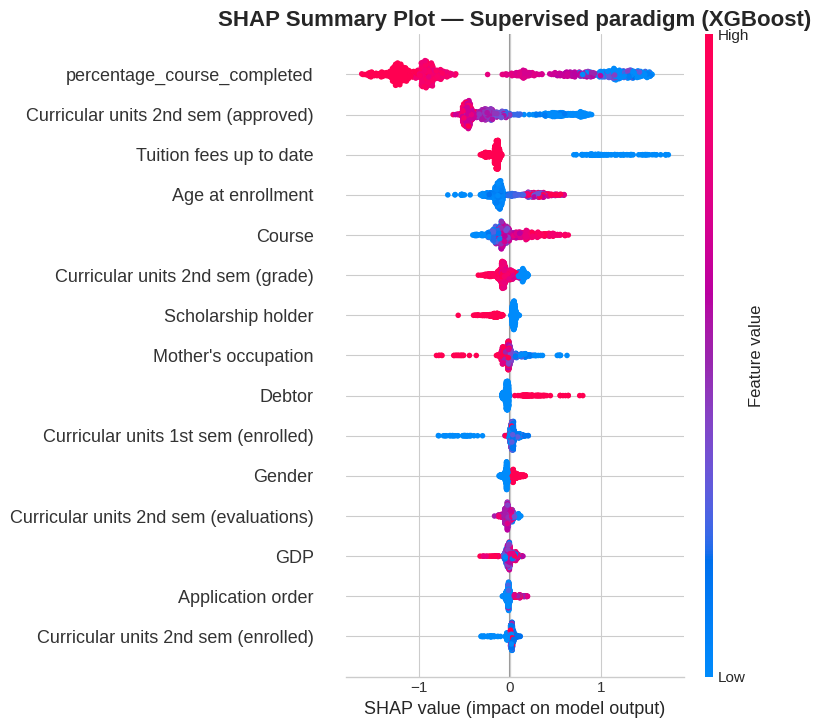

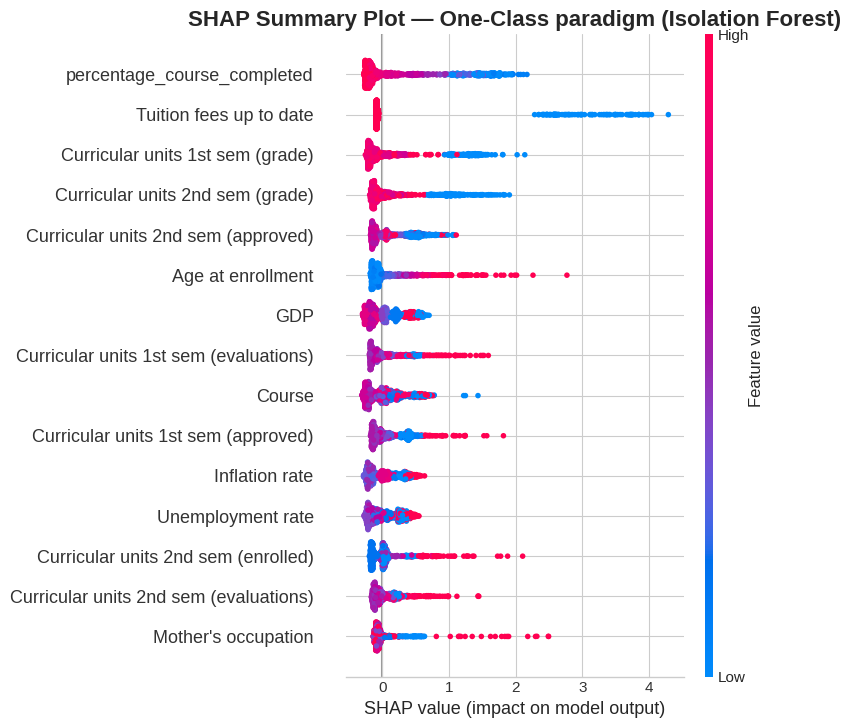

In [24]:
# %% [R6] Item 10
plt.rcParams.update({'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14, 'xtick.labelsize': 13, 'ytick.labelsize': 13, 'legend.fontsize': 13})
en = lambda L: [x.replace('percentage_course_completed', 'percentage_course_completed') for x in L]

plt.figure(figsize=(11, 7))
shap.summary_plot(shap_values_xgb, X_test, feature_names=en(feature_names), max_display=15, show=False)
plt.title('SHAP Summary Plot — Supervised paradigm (XGBoost)', fontweight='bold'); plt.tight_layout()
plt.savefig(caminho_saida('shap_summary_supervisionado.png', 'figuras'), dpi=300, bbox_inches='tight'); plt.show()

plt.figure(figsize=(11, 7))
shap.summary_plot(shap_values_if, X_test[:, top20_idx], feature_names=en([feature_names[i] for i in top20_idx]), max_display=15, show=False)
plt.title('SHAP Summary Plot — One-Class paradigm (Isolation Forest)', fontweight='bold'); plt.tight_layout()
plt.savefig(caminho_saida('shap_summary_oneclass.png', 'figuras'), dpi=300, bbox_inches='tight'); plt.show()


In [25]:
# %% [CELL R7] Selected Random Forest hyperparameters
# Reads the best hyperparameters directly from the pipelines already trained in models_store (retrains nothing).

rf_modelos = [k for k in models_store if k.startswith('Random Forest')]
assert rf_modelos, 'Run Cell 10 first: models_store does not contain the Random Forests.'

# 1) Check: the MCC must reproduce the values in Table 3 (SMOTE = 0.7530)
from sklearn.metrics import matthews_corrcoef
print('=== Reproduction check (MCC on the test set) ===')
for k in rf_modelos:
    print(f'  {k:42s} MCC = {matthews_corrcoef(y_test, preds_store[k]["y_pred"]):.4f}')

# 2) Hyperparameters as a list
print('\n=== Selected hyperparameters ===')
for k in rf_modelos:
    c = models_store[k].named_steps['clf']
    print(f'  {k:42s} n_estimators={c.n_estimators} | max_depth={c.max_depth} | '
          f'min_samples_split={c.min_samples_split} | min_samples_leaf={c.min_samples_leaf} | '
          f'max_features={c.max_features}')

# 3) Ready-to-paste rows for the LaTeX table (replace the six red rows)
print('\n=== LaTeX rows ===')
for k in rf_modelos:
    c = models_store[k].named_steps['clf']
    nome = k.replace('Random Forest + ', '')
    print(f"\\quad + {nome} & & {c.n_estimators} trees; depth {c.max_depth}; "
          f"min.\\ split {c.min_samples_split}; min.\\ leaf {c.min_samples_leaf}; "
          f"\\texttt{{{c.max_features}}} \\\\")

=== Reproduction check (MCC on the test set) ===
  Random Forest + SMOTE                      MCC = 0.7530
  Random Forest + RandomOverSampler          MCC = 0.7313
  Random Forest + RandomUnderSampler         MCC = 0.7098
  Random Forest + NearMiss                   MCC = 0.5699
  Random Forest + SMOTETomek                 MCC = 0.7241
  Random Forest + SMOTEENN                   MCC = 0.7058

=== Selected hyperparameters ===
  Random Forest + SMOTE                      n_estimators=300 | max_depth=24 | min_samples_split=2 | min_samples_leaf=2 | max_features=log2
  Random Forest + RandomOverSampler          n_estimators=200 | max_depth=24 | min_samples_split=10 | min_samples_leaf=4 | max_features=sqrt
  Random Forest + RandomUnderSampler         n_estimators=150 | max_depth=21 | min_samples_split=10 | min_samples_leaf=1 | max_features=sqrt
  Random Forest + NearMiss                   n_estimators=300 | max_depth=5 | min_samples_split=7 | min_samples_leaf=3 | max_features=log2
  Random